# 02 – Digester batch analysis (D1–D4)

Reads only `data/batch_master.csv` and `data/lab_linked.csv` (made by `01_build_master.ipynb`) – fast, no PI access.
The order follows `workflow.md`: **baseline quality → Step 1 chips → Step 2 prehydrolysis → Step 3 heat & cook → Step 4 displacement → link to lab**.

Settings at the top: `ONLY_OK_BATCHES` (use only batches with `quality_flag == "ok"`).

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import config

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 80)

from build_master import load_outputs

ONLY_OK_BATCHES = True

master, lab_linked = load_outputs()
if ONLY_OK_BATCHES:
    master = master[master["quality_flag"] == "ok"]
print("Batches:", len(master), "| per digester:", master["digester"].value_counts().sort_index().to_dict())

LAB_LABELS = {"press1_kappa": "Kappa", "press1_viscosity": "Viscosity", "press1_brightness": "Brightness"}


def volatility_table(columns):
    """N, Mean, SD, CV%, Min, Max per digester for each column."""
    rows = []
    for col in columns:
        if col not in master:
            continue
        for dig, vals in master.groupby("digester")[col]:
            vals = vals.dropna()
            rows.append({"Parameter": col, "Digester": f"D{dig}", "N": len(vals), "Mean": vals.mean(),
                         "SD": vals.std(), "CV%": 100 * vals.std() / vals.mean() if vals.mean() else np.nan,
                         "Min": vals.min(), "Max": vals.max()})
    return pd.DataFrame(rows).set_index(["Parameter", "Digester"]).round(2)


def boxplots(columns, title):
    """One boxplot per column, D1-D4 side by side."""
    columns = [c for c in columns if c in master]
    fig, axes = plt.subplots(1, len(columns), figsize=(4.5 * len(columns), 4.5))
    for ax, col in zip(np.atleast_1d(axes), columns):
        sns.boxplot(data=master, x="digester", y=col, ax=ax)
        ax.set_title(col, fontsize=9)
        ax.set_xlabel("Digester")
        ax.set_ylabel("")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

Batches: 2909 | per digester: {1: 841, 2: 854, 3: 855, 4: 359}


## Quality map – Kappa vs Viscosity per digester

One scatter per digester (D1–D4) from `master` (1 point = 1 batch). Outliers beyond `SIGMA` sd are dropped per digester, on both axes. Change `X_COL` / `Y_COL` / `SIGMA` to plot other pairs. A `CLUSTER_K` hook is left for a future k-means colouring.

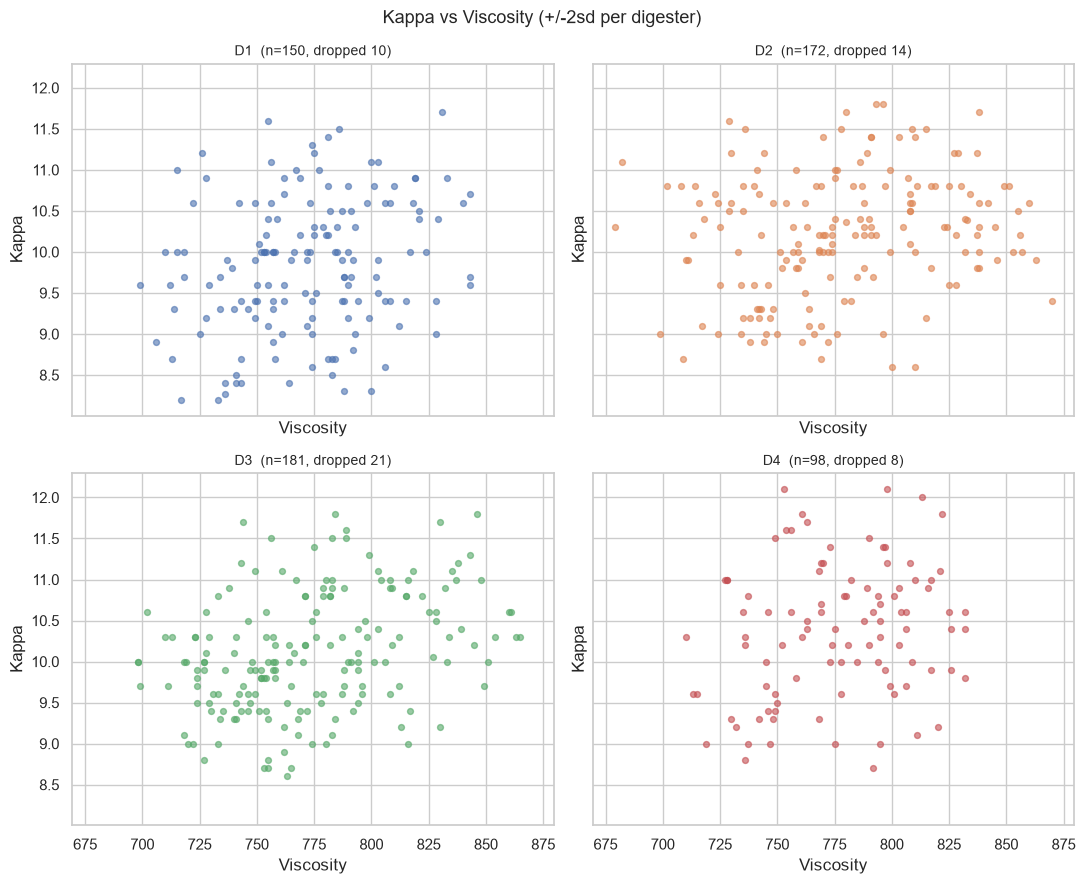

In [2]:
X_COL = "press1_viscosity"        # x axis
Y_COL = "press1_kappa"    # y axis
SIGMA = 2                     # drop points beyond this many sd (per digester)
CLUSTER_K = None              # future: set an int to colour by k-means instead of one colour


def within_sigma(s, sigma=SIGMA):
    """Boolean mask: value within mean +/- sigma*sd (NaN -> False)."""
    m, sd = s.mean(), s.std()
    if not sd:
        return s.notna()
    return (s - m).abs() <= sigma * sd


def quality_scatter(x_col=X_COL, y_col=Y_COL, sigma=SIGMA):
    """2x2 scatter of y vs x, one digester per panel, outliers trimmed per digester."""
    digs = sorted(master["digester"].dropna().unique())
    fig, axes = plt.subplots(2, 2, figsize=(11, 9), sharex=True, sharey=True)
    for ax, dig in zip(axes.ravel(), digs):
        sub = master[master["digester"] == dig][[x_col, y_col]].dropna()
        keep = within_sigma(sub[x_col], sigma) & within_sigma(sub[y_col], sigma)
        sub, n_out = sub[keep], int((~keep).sum())
        ax.scatter(sub[x_col], sub[y_col], s=18, alpha=0.6, color=f"C{int(dig) - 1}")
        ax.set_title(f"D{int(dig)}  (n={len(sub)}, dropped {n_out})", fontsize=10)
        ax.set_xlabel(LAB_LABELS.get(x_col, x_col))
        ax.set_ylabel(LAB_LABELS.get(y_col, y_col))
    for ax in axes.ravel()[len(digs):]:
        ax.set_visible(False)
    fig.suptitle(f"{LAB_LABELS.get(y_col, y_col)} vs {LAB_LABELS.get(x_col, x_col)} (+/-{sigma}sd per digester)", fontsize=13)
    plt.tight_layout()
    plt.show()


quality_scatter()

## Process values by quality grade, per digester

For each digester, split the batches by their lab grade (`low` / `normal` / `high`) and show the typical value of each process parameter in that group. The value is `median (Q1–Q3)` so outliers do not shift it; the `n` row is the batch count per group. Compare the `normal` column across parameters to read off "when quality is normal, this parameter sits around here".

Change `GRADE_COL` (`viscosity_grade` / `kappa_grade`) or `PARAMS` to look at other targets or sensors. Grades are provisional (`config.QUALITY_TARGETS`). `normal` groups are small, so treat this as a hypothesis, not a confirmed setpoint.

In [3]:
GRADE_COL = "viscosity_grade"     # viscosity_grade or kappa_grade
GRADE_ORDER = ["low", "normal", "high"]
PARAMS = [                         # workflow X parameters to profile (edit freely)
    "h_factor",
    "white_liquor_m3",
    "white_liquor_per_ton_chip",
    "liquor_to_wood_ratio",
    "chip_weight_max_chip_filling",
    "circulation_temp_max_heat_and_cook",
    "digester_pressure_mean_heat_and_cook",
    "steam_to_heater_flow_mean_heat_and_cook",
    "steam_heater_temp_max_heat_and_cook",
    "alkali_accumulator1_conc_mean_hot_liquor_filling",
    "alkali_accumulator2_conc_mean_hot_liquor_filling",
    "black_liquor_conductivity_mean_displacement",
    "pfactor_actual_last_prehydrolysis",
    "pfactor_setpoint_last_prehydrolysis",
    "hbl_accumulator_cond_mean_hot_liquor_filling",

]


def _cell(s):
    """median (Q1-Q3) of a series, or '-' if empty."""
    s = s.dropna()
    if s.empty:
        return "-"
    return f"{s.median():.1f} ({s.quantile(.25):.1f}\u2013{s.quantile(.75):.1f})"


def grade_summary(dig, grade_col=GRADE_COL, params=PARAMS):
    """One digester: rows = params, columns = grade groups, value = median (Q1-Q3)."""
    sub = master[(master["digester"] == dig) & master[grade_col].notna()]
    cols = [g for g in GRADE_ORDER if g in sub[grade_col].unique()]
    rows = {p: {g: _cell(sub[sub[grade_col] == g][p]) for g in cols}
            for p in params if p in sub.columns}
    table = pd.DataFrame(rows).T
    table.loc["n (batches)"] = {g: int((sub[grade_col] == g).sum()) for g in cols}
    return table


for dig in sorted(master["digester"].dropna().unique()):
    print(f"\n=== D{int(dig)} — process values by {GRADE_COL} ===")
    display(grade_summary(dig))


=== D1 — process values by viscosity_grade ===


,low,normal,high
h_factor,510.6 (507.9–513.3),540.9 (502.5–577.0),475.2 (457.6–517.8)
white_liquor_m3,13.1 (13.1–13.2),13.2 (12.9–14.1),12.9 (12.8–14.3)
white_liquor_per_ton_chip,0.1 (0.1–0.1),0.1 (0.1–0.2),0.1 (0.1–0.2)
liquor_to_wood_ratio,1.6 (1.5–1.6),1.6 (1.5–1.7),1.4 (1.4–1.5)
chip_weight_max_chip_filling,91.8 (91.1–92.4),91.4 (87.1–95.1),95.6 (92.3–98.4)
circulation_temp_max_heat_and_cook,157.1 (156.2–158.0),157.3 (156.5–158.3),156.8 (156.1–157.9)
digester_pressure_mean_heat_and_cook,6.1 (6.1–6.2),6.2 (6.1–6.3),6.1 (6.1–6.2)
steam_to_heater_flow_mean_heat_and_cook,4.3 (3.5–5.0),2.6 (-0.0–6.1),2.1 (-1.6–4.5)
steam_heater_temp_max_heat_and_cook,163.2 (162.9–163.6),162.8 (162.2–163.4),163.0 (162.6–163.6)
alkali_accumulator1_conc_mean_hot_liquor_filling,37.5 (37.3–37.6),36.8 (36.4–37.2),36.1 (35.9–36.6)



=== D2 — process values by viscosity_grade ===


,low,normal,high
h_factor,341.4 (317.9–482.8),362.0 (324.9–413.8),323.7 (308.2–353.1)
white_liquor_m3,13.9 (12.8–15.8),13.2 (12.9–13.9),12.9 (12.8–13.2)
white_liquor_per_ton_chip,0.1 (0.1–0.1),0.1 (0.1–0.2),0.1 (0.1–0.1)
liquor_to_wood_ratio,1.4 (1.4–1.5),1.5 (1.4–1.6),1.5 (1.4–1.6)
chip_weight_max_chip_filling,95.2 (94.1–96.9),91.6 (88.2–96.8),93.3 (89.6–96.0)
circulation_temp_max_heat_and_cook,158.6 (157.5–159.6),159.0 (158.5–159.9),159.2 (158.6–159.8)
digester_pressure_mean_heat_and_cook,6.2 (6.0–6.2),6.2 (6.1–6.3),6.2 (6.1–6.3)
steam_to_heater_flow_mean_heat_and_cook,2.2 (1.3–3.3),2.5 (1.6–3.5),3.0 (2.2–3.9)
steam_heater_temp_max_heat_and_cook,161.1 (160.7–161.9),161.8 (160.7–162.6),161.7 (161.0–162.1)
alkali_accumulator1_conc_mean_hot_liquor_filling,37.1 (36.9–37.9),37.0 (36.5–37.3),36.0 (35.9–36.5)



=== D3 — process values by viscosity_grade ===


,low,normal,high
h_factor,277.6 (272.5–302.7),338.5 (305.7–371.5),300.2 (277.0–320.6)
white_liquor_m3,14.9 (13.2–16.0),14.0 (12.9–14.3),13.0 (12.8–14.1)
white_liquor_per_ton_chip,0.2 (0.2–0.2),0.2 (0.2–0.2),0.2 (0.1–0.2)
liquor_to_wood_ratio,1.6 (1.5–1.7),1.8 (1.7–2.0),1.8 (1.7–1.9)
chip_weight_max_chip_filling,91.5 (89.4–93.8),85.0 (81.0–89.0),84.9 (81.7–88.0)
circulation_temp_max_heat_and_cook,157.9 (157.3–158.0),157.9 (157.1–158.9),157.7 (156.9–158.5)
digester_pressure_mean_heat_and_cook,5.7 (5.4–5.9),6.1 (5.7–6.2),5.9 (5.7–6.1)
steam_to_heater_flow_mean_heat_and_cook,2.7 (1.4–3.0),1.5 (0.7–2.2),1.4 (0.0–2.0)
steam_heater_temp_max_heat_and_cook,160.9 (160.2–161.4),157.9 (156.4–160.6),158.7 (156.8–159.7)
alkali_accumulator1_conc_mean_hot_liquor_filling,37.9 (36.4–38.0),37.0 (36.5–37.2),36.1 (36.0–37.1)



=== D4 — process values by viscosity_grade ===


,low,normal,high
h_factor,380.7 (323.5–519.4),451.3 (364.3–557.2),350.7 (282.5–401.6)
white_liquor_m3,16.4 (13.7–19.9),13.2 (12.9–14.0),12.9 (12.9–13.9)
white_liquor_per_ton_chip,0.2 (0.2–0.2),0.2 (0.2–0.2),0.2 (0.2–0.2)
liquor_to_wood_ratio,1.5 (1.4–1.5),1.6 (1.5–1.7),1.6 (1.5–1.7)
chip_weight_max_chip_filling,75.0 (74.8–78.7),71.8 (68.4–74.0),71.0 (68.6–73.7)
circulation_temp_max_heat_and_cook,158.5 (157.9–158.9),158.8 (158.0–159.9),158.2 (157.9–158.9)
digester_pressure_mean_heat_and_cook,6.3 (6.3–6.3),6.2 (6.1–6.3),6.2 (6.1–6.3)
steam_to_heater_flow_mean_heat_and_cook,20.9 (20.9–21.0),21.0 (20.9–21.0),21.0 (20.9–21.0)
steam_heater_temp_max_heat_and_cook,162.4 (161.9–162.9),161.9 (160.6–162.9),161.9 (161.4–162.5)
alkali_accumulator1_conc_mean_hot_liquor_filling,38.0 (37.9–38.0),37.1 (36.5–37.9),36.4 (36.0–36.6)


### Process values by combined Kappa+Viscosity grade

`overall_grade` = **normal** only when Kappa *and* Viscosity are both `normal`; otherwise **abnormal**. If either grade is missing the batch is dropped (NaN). Same median (Q1–Q3) layout, one table per digester. `normal` count is small because both targets must land together — treat as a hypothesis, not a conclusion.

In [4]:
OVERALL_ORDER = ["abnormal", "normal"]   # overall_grade comes from build_master (normal only if every target is normal)


def overall_summary(dig, params=PARAMS):
    """One digester: rows = params, columns = abnormal/normal, value = median (Q1-Q3)."""
    sub = master[(master["digester"] == dig) & master["overall_grade"].notna()]
    cols = [g for g in OVERALL_ORDER if g in sub["overall_grade"].unique()]
    rows = {p: {g: _cell(sub[sub["overall_grade"] == g][p]) for g in cols}
            for p in params if p in sub.columns}
    table = pd.DataFrame(rows).T
    table.loc["n (batches)"] = {g: int((sub["overall_grade"] == g).sum()) for g in cols}
    return table


for dig in sorted(master["digester"].dropna().unique()):
    print(f"\n=== D{int(dig)} — process values by overall_grade (Kappa+Viscosity) ===")
    
    display(overall_summary(dig))


=== D1 — process values by overall_grade (Kappa+Viscosity) ===


,abnormal,normal
h_factor,511.9 (468.6–555.9),544.9 (503.5–570.1)
white_liquor_m3,13.0 (12.9–14.1),13.2 (12.9–14.1)
white_liquor_per_ton_chip,0.1 (0.1–0.2),0.1 (0.1–0.2)
liquor_to_wood_ratio,1.5 (1.4–1.6),1.6 (1.5–1.7)
chip_weight_max_chip_filling,93.6 (90.1–96.6),90.6 (86.6–94.9)
circulation_temp_max_heat_and_cook,157.1 (156.3–158.0),157.3 (156.4–158.3)
digester_pressure_mean_heat_and_cook,6.2 (6.1–6.2),6.2 (6.1–6.3)
steam_to_heater_flow_mean_heat_and_cook,2.7 (-0.3–5.7),2.5 (-0.1–6.2)
steam_heater_temp_max_heat_and_cook,162.9 (162.4–163.5),162.9 (162.2–163.4)
alkali_accumulator1_conc_mean_hot_liquor_filling,36.7 (36.1–37.2),36.5 (36.2–37.1)



=== D2 — process values by overall_grade (Kappa+Viscosity) ===


,abnormal,normal
h_factor,337.3 (315.4–393.3),382.0 (333.0–422.8)
white_liquor_m3,13.0 (12.9–13.9),13.2 (13.0–13.9)
white_liquor_per_ton_chip,0.1 (0.1–0.1),0.1 (0.1–0.2)
liquor_to_wood_ratio,1.5 (1.4–1.6),1.6 (1.4–1.6)
chip_weight_max_chip_filling,93.3 (89.2–96.7),90.3 (87.9–95.2)
circulation_temp_max_heat_and_cook,159.0 (158.3–159.8),159.2 (158.8–160.1)
digester_pressure_mean_heat_and_cook,6.2 (6.1–6.3),6.2 (6.1–6.3)
steam_to_heater_flow_mean_heat_and_cook,2.7 (1.8–3.6),2.5 (1.5–3.8)
steam_heater_temp_max_heat_and_cook,161.6 (160.7–162.3),161.9 (161.0–162.9)
alkali_accumulator1_conc_mean_hot_liquor_filling,36.5 (36.0–37.2),36.8 (36.5–37.1)



=== D3 — process values by overall_grade (Kappa+Viscosity) ===


,abnormal,normal
h_factor,306.5 (282.8–327.3),343.2 (317.7–379.5)
white_liquor_m3,13.2 (12.9–14.2),14.0 (12.9–14.3)
white_liquor_per_ton_chip,0.2 (0.1–0.2),0.2 (0.2–0.2)
liquor_to_wood_ratio,1.8 (1.7–1.9),1.9 (1.7–2.0)
chip_weight_max_chip_filling,86.5 (82.5–88.8),83.7 (80.4–89.2)
circulation_temp_max_heat_and_cook,157.8 (156.9–158.7),158.0 (157.1–159.0)
digester_pressure_mean_heat_and_cook,6.0 (5.7–6.2),6.1 (5.9–6.3)
steam_to_heater_flow_mean_heat_and_cook,1.5 (0.5–2.3),1.5 (0.7–2.0)
steam_heater_temp_max_heat_and_cook,158.9 (156.7–160.9),157.6 (156.6–159.7)
alkali_accumulator1_conc_mean_hot_liquor_filling,36.5 (36.0–37.2),37.0 (36.5–37.2)



=== D4 — process values by overall_grade (Kappa+Viscosity) ===


,abnormal,normal
h_factor,399.7 (310.1–506.3),462.7 (361.9–540.6)
white_liquor_m3,13.0 (12.9–14.1),13.1 (12.9–13.9)
white_liquor_per_ton_chip,0.2 (0.2–0.2),0.2 (0.2–0.2)
liquor_to_wood_ratio,1.6 (1.5–1.7),1.6 (1.5–1.7)
chip_weight_max_chip_filling,72.1 (68.8–74.8),71.5 (68.3–72.6)
circulation_temp_max_heat_and_cook,158.5 (158.0–159.4),158.6 (157.8–159.7)
digester_pressure_mean_heat_and_cook,6.2 (6.1–6.3),6.2 (6.1–6.2)
steam_to_heater_flow_mean_heat_and_cook,21.0 (20.9–21.0),21.0 (20.0–21.0)
steam_heater_temp_max_heat_and_cook,161.9 (161.0–162.9),161.4 (149.7–162.5)
alkali_accumulator1_conc_mean_hot_liquor_filling,36.9 (36.3–37.5),37.2 (36.5–38.0)


## Correlation: lab quality vs process parameters, per digester

Spearman rank correlation between the 3 Press 1 lab values (rows) and the process parameters (columns), one heatmap per digester. 
Red = positive, blue = negative. Only pairs with at least `MIN_N` batches are scored.

Add or drop parameters by editing `PARAMS`. **Note:** these come from lab-linked batch values with no lag/production adjustment, so they are *hypotheses*, not findings.

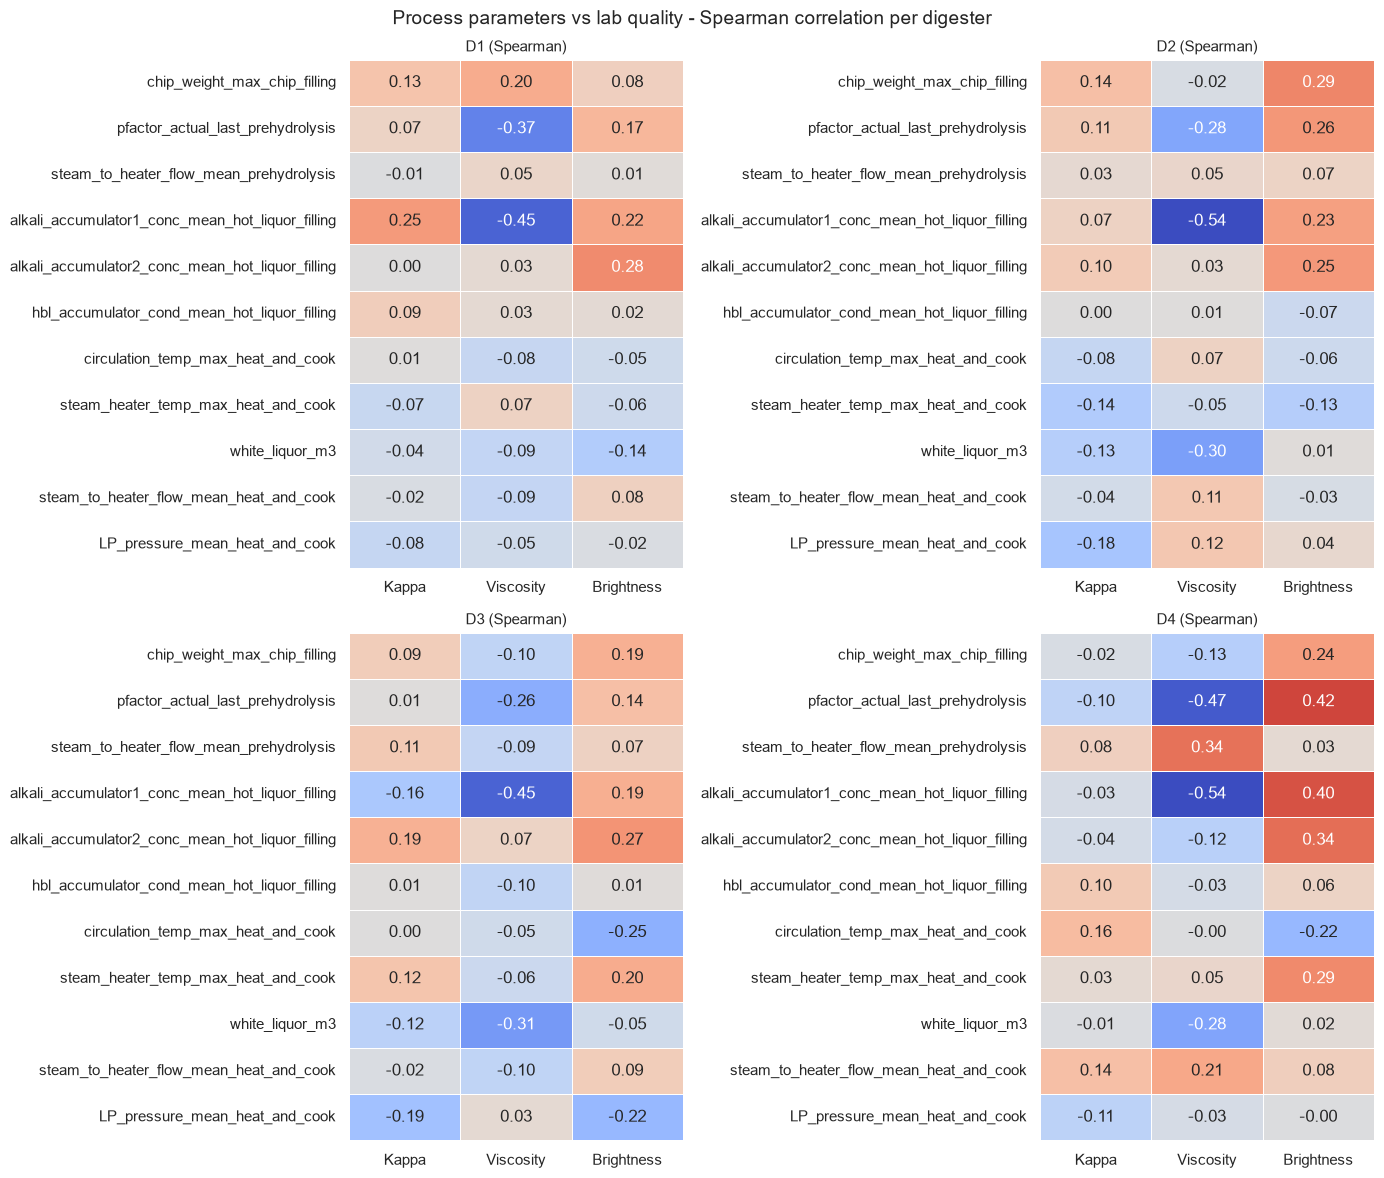

In [18]:
from scipy.stats import spearmanr

MIN_N = 5                                  # skip a pair with fewer batches
LAB_COLS = ["press1_kappa", "press1_viscosity", "press1_brightness"]   # x axis
PARAMS = [                                 # y axis - edit freely
    "chip_weight_max_chip_filling",
    "pfactor_actual_last_prehydrolysis",
    "steam_to_heater_flow_mean_prehydrolysis",
    "alkali_accumulator1_conc_mean_hot_liquor_filling",
    "alkali_accumulator2_conc_mean_hot_liquor_filling",
    "hbl_accumulator_cond_mean_hot_liquor_filling",
    "circulation_temp_max_heat_and_cook",
    "steam_heater_temp_max_heat_and_cook",
    "white_liquor_m3",
    "steam_to_heater_flow_mean_heat_and_cook",
    "LP_pressure_mean_heat_and_cook",
    "LP_pressure_mean_prehydrolysis"
]
PARAMS = [p for p in PARAMS if p in master.columns]


def corr_matrix(dig):
    d = master[master["digester"] == dig]
    out = pd.DataFrame(index=PARAMS, columns=LAB_COLS, dtype=float)
    for p in PARAMS:
        for lab in LAB_COLS:
            pair = d[[p, lab]].dropna()
            if len(pair) >= MIN_N:
                out.loc[p, lab] = spearmanr(pair[p], pair[lab])[0]
    return out.astype(float)


fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, dig in zip(axes.flatten(), sorted(master["digester"].dropna().unique())):
    m = corr_matrix(dig)
    sns.heatmap(m, 
                annot=True, 
                fmt=".2f", 
                cmap="coolwarm", 
                center=0, 
                vmin=-0.5, 
                vmax=0.5,
                cbar=False, 
                linewidths=0.5, 
                ax=ax,
                xticklabels=[LAB_LABELS[c] for c in m.columns])
    ax.set_title(f"D{int(dig)} (Spearman)", fontsize=11)
    ax.set_ylabel("")
fig.suptitle("Process parameters vs lab quality - Spearman correlation per digester", fontsize=14)
plt.tight_layout()
plt.show()

## Phase 1 – Baseline: Press 1 lab quality per digester

Real lab samples only. Green band = SOP (`config.LAB_SOP_LIMITS`, **not yet confirmed**).

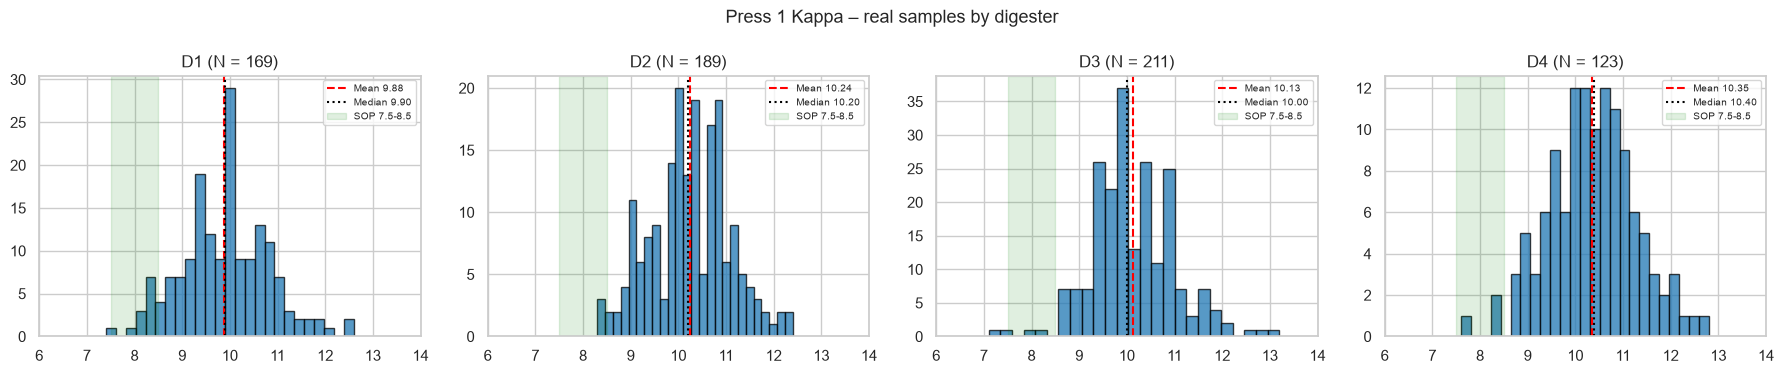

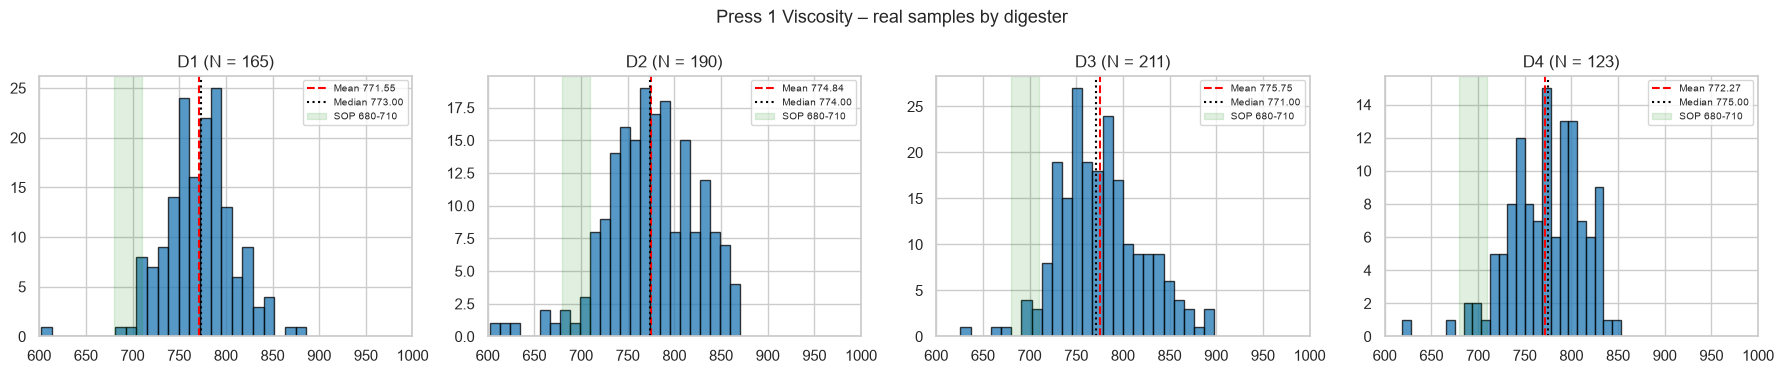

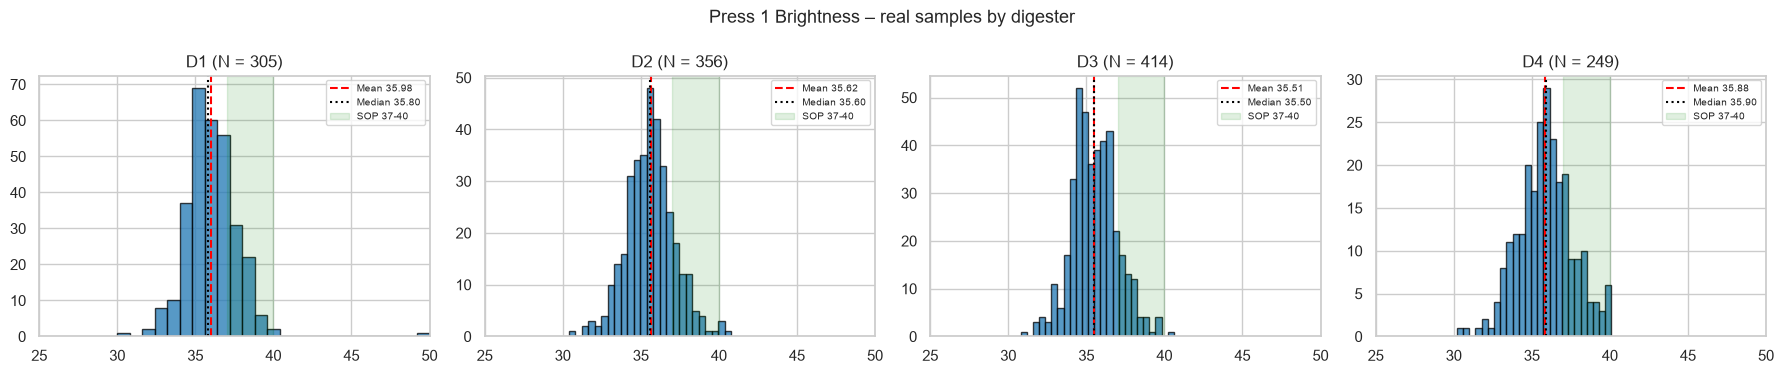

N    Mean  Median     SD
parameter         digester                            
press1_brightness 1         305   35.98    35.8   1.69
                  2         356   35.62    35.6   1.54
                  3         414   35.51    35.5   1.46
                  4         249   35.88    35.9   1.77
press1_kappa      1         169    9.88     9.9   0.92
                  2         189   10.24    10.2   0.83
                  3         211   10.13    10.0   0.88
                  4         123   10.35    10.4   0.91
press1_viscosity  1         165  771.55   773.0  37.37
                  2         190  774.84   774.0  47.81
                  3         211  775.75   771.0  44.74
                  4         123  772.27   775.0  39.45

In [6]:
HIST_XLIM = {"press1_kappa": (6, 14), "press1_viscosity": (600, 1000), "press1_brightness": (25, 50)}

for param, label in LAB_LABELS.items():
    data = lab_linked[lab_linked["parameter"] == param]
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharex=True)
    for ax, dig in zip(axes, [1, 2, 3, 4]):
        vals = data.loc[data["digester"] == dig, "value"].dropna()
        ax.hist(vals, bins=25, color="#1f77b4", edgecolor="black", alpha=0.75)
        ax.axvline(vals.mean(), color="red", linestyle="--", label=f"Mean {vals.mean():.2f}")
        ax.axvline(vals.median(), color="black", linestyle=":", label=f"Median {vals.median():.2f}")
        lo, hi = config.LAB_SOP_LIMITS[param]
        ax.axvspan(lo, hi, color="green", alpha=0.12, label=f"SOP {lo}-{hi}")
        ax.set_xlim(HIST_XLIM[param])
        ax.set_title(f"D{dig} (N = {len(vals)})")
        ax.legend(fontsize=7)
    fig.suptitle(f"Press 1 {label} – real samples by digester", fontsize=13)
    plt.tight_layout()
    plt.show()

summary = (lab_linked.groupby(["parameter", "digester"])["value"]
           .agg(N="count", Mean="mean", Median="median", SD="std").round(2))
display(summary)

### Lab trend over time (24 h rolling mean)

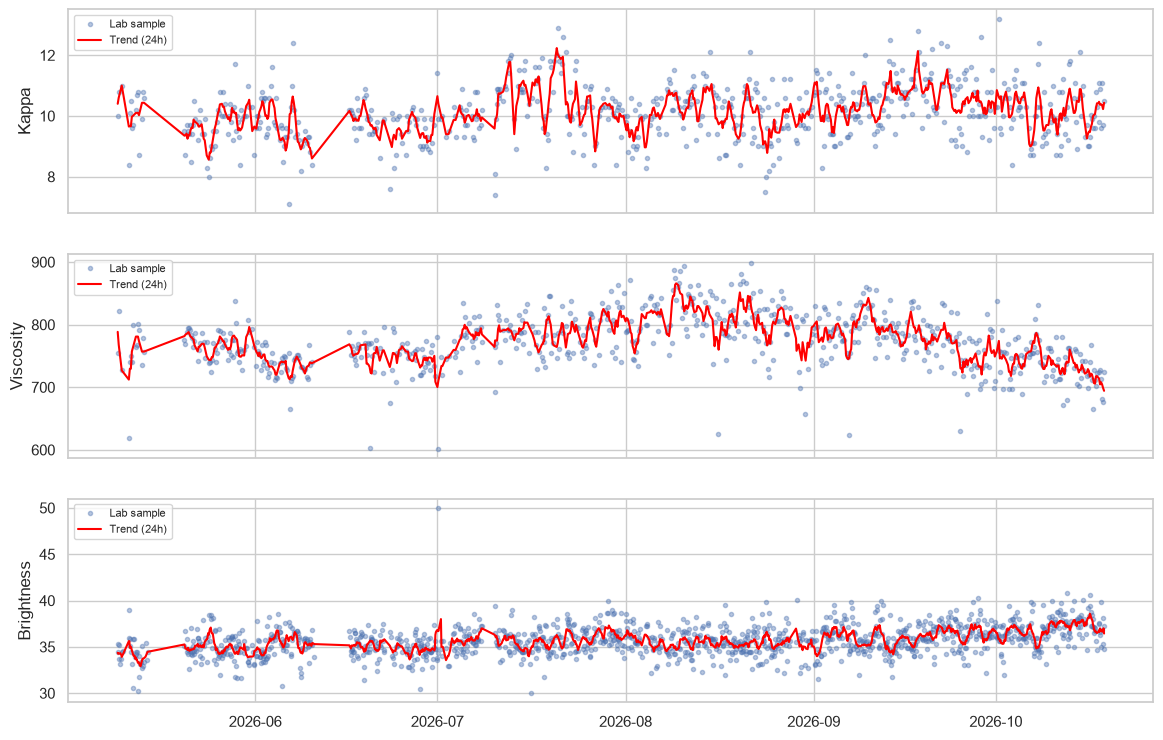

In [7]:
TREND_WINDOW = "24h"

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, (param, label) in zip(axes, LAB_LABELS.items()):
    s = (lab_linked[lab_linked["parameter"] == param]
         .drop_duplicates("timestamp").set_index("timestamp")["value"].sort_index().dropna())
    ax.plot(s.index, s, ".", alpha=0.4, label="Lab sample")
    ax.plot(s.index, s.rolling(TREND_WINDOW, center=True, min_periods=1).mean(), color="red",
            label=f"Trend ({TREND_WINDOW})")
    ax.set_ylabel(label)
    ax.legend(fontsize=8, loc="upper left")
plt.show()

## Step 1 – Input & preparation (chips)

- `chip_weight_max_chip_filling` – chips loaded (wet weight, ton; chip moisture tag is not usable)
- `liquor_to_wood_ratio` – liquor added per ton of wet chips (approximate L:W)
- `white_liquor_m3`, `white_liquor_per_ton_chip` – white liquor added in HOT LIQUOR FILLING, and per ton of wet chips (same recipe volume + fewer chips = more alkali per ton)
- `ventilation_temp_max_chip_filling`, `chip_filling_minutes`

N   Mean     SD    CV%    Min  \
Parameter                         Digester                                    
chip_weight_max_chip_filling      D1        841  91.00   6.43   7.06  51.25   
                                  D2        854  91.83   5.40   5.88  74.94   
                                  D3        855  84.83   6.62   7.81  56.56   
                                  D4        359  71.50   5.00   6.99  50.01   
liquor_to_wood_ratio              D1        841   1.58   0.20  12.66   1.02   
                                  D2        854   1.53   0.15   9.61   1.11   
                                  D3        855   1.84   0.23  12.66   1.26   
                                  D4        359   1.62   0.19  11.70   1.09   
white_liquor_m3                   D1        841  13.63   1.48  10.84  10.20   
                                  D2        854  13.47   1.77  13.14  10.11   
                                  D3        855  13.81   1.59  11.50  10.19   
                                  D4        359  13.85   1.80  13.00  11.20   
white_liquor_per_ton_chip         D1        841   0.15   0.02  13.56   0.10   
                                  D2        854   0.15   0.02  14.07   0.10   
                                  D3        855   0.16   0.02  13.98   0.11   
                                  D4        359   0.19   0.03  14.88   0.14   
ventilation_temp_max_chip_filling D1        841  90.37   1.66   1.84  85.00   
                                  D2        854  92.05   2.59   2.81  86.46   
                                  D3        855  90.82   2.78   3.06  79.58   
                                  D4        359  90.02   1.47   1.64  75.66   
chip_filling_minutes              D1        841  35.48  11.81  33.29  15.00   
                                  D2        854  36.86  12.36  33.54  20.00   
                                  D3        855  35.25  15.19  43.08  20.00   
                                  D4        359  35.24   6.57  18.65  10.00   

                                               Max  
Parameter                         Digester          
chip_weight_max_chip_filling      D1        115.25  
                                  D2        110.59  
                                  D3        106.99  
                                  D4         90.63  
liquor_to_wood_ratio              D1          3.56  
                                  D2          2.09  
                                  D3          3.25  
                                  D4          2.66  
white_liquor_m3                   D1         22.09  
                                  D2         46.63  
                                  D3         24.94  
                                  D4         24.92  
white_liquor_per_ton_chip         D1          0.31  
                                  D2          0.49  
                                  D3          0.30  
                                  D4          0.38  
ventilation_temp_max_chip_filling D1        105.92  
                                  D2        100.53  
                                  D3        128.28  
                                  D4         97.61  
chip_filling_minutes              D1        275.00  
                                  D2        235.00  
                                  D3        385.00  
                                  D4         80.00

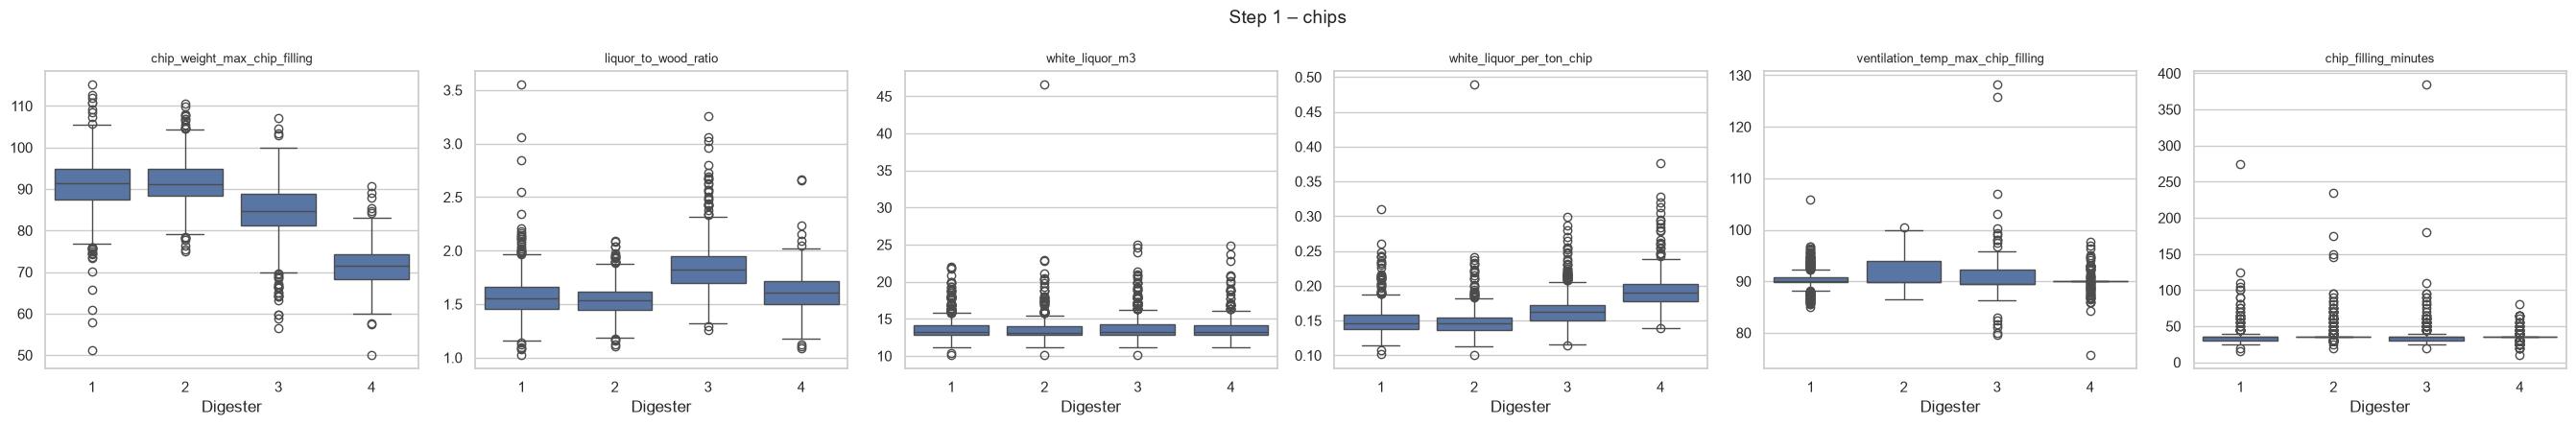

In [8]:
STEP1 = ["chip_weight_max_chip_filling", "liquor_to_wood_ratio",
         "white_liquor_m3", "white_liquor_per_ton_chip", "ventilation_temp_max_chip_filling", "chip_filling_minutes"]
display(volatility_table(STEP1))
boxplots(STEP1, "Step 1 – chips")

## Step 2 – Prehydrolysis

- `pfactor_actual_last_prehydrolysis` vs `pfactor_setpoint_last_prehydrolysis`; `pfactor_gap` = actual − setpoint
- `digester_pressure_max_prehydrolysis`, `prehydrolysis_minutes`

N    Mean     SD    CV%  \
Parameter                           Digester                              
pfactor_actual_last_prehydrolysis   D1        841  339.57  32.39   9.54   
                                    D2        854  343.62  31.82   9.26   
                                    D3        855  343.99  30.65   8.91   
                                    D4        359  356.23  38.22  10.73   
pfactor_setpoint_last_prehydrolysis D1        841  363.04  29.25   8.06   
                                    D2        854  363.38  29.18   8.03   
                                    D3        855  363.30  29.33   8.07   
                                    D4        359  376.69  35.18   9.34   
pfactor_gap                         D1        841  -23.47  14.83 -63.16   
                                    D2        854  -19.76  15.45 -78.20   
                                    D3        855  -19.31  13.98 -72.40   
                                    D4        359  -20.46  12.56 -61.40   
digester_pressure_max_prehydrolysis D1        841    8.38   0.35   4.15   
                                    D2        854    8.43   0.25   2.99   
                                    D3        855    8.43   0.26   3.10   
                                    D4        359    8.21   0.50   6.05   
prehydrolysis_minutes               D1        841   73.79   9.42  12.77   
                                    D2        854   75.06  16.50  21.98   
                                    D3        855   74.11  10.78  14.54   
                                    D4        359   81.77  11.84  14.48   

                                                 Min     Max  
Parameter                           Digester                  
pfactor_actual_last_prehydrolysis   D1        259.05  452.96  
                                    D2        273.64  509.53  
                                    D3        269.25  486.81  
                                    D4        259.15  450.31  
pfactor_setpoint_last_prehydrolysis D1        310.00  460.00  
                                    D2        320.00  460.00  
                                    D3        320.00  460.00  
                                    D4        320.00  460.00  
pfactor_gap                         D1        -62.11    1.59  
                                    D2        -72.84  189.53  
                                    D3        -55.87  106.81  
                                    D4        -64.13    0.63  
digester_pressure_max_prehydrolysis D1          7.10   11.06  
                                    D2          7.12   10.71  
                                    D3          7.05   10.14  
                                    D4          7.15   10.45  
prehydrolysis_minutes               D1         55.00  150.00  
                                    D2         45.00  410.00  
                                    D3         55.00  270.00  
                                    D4         55.00  115.00

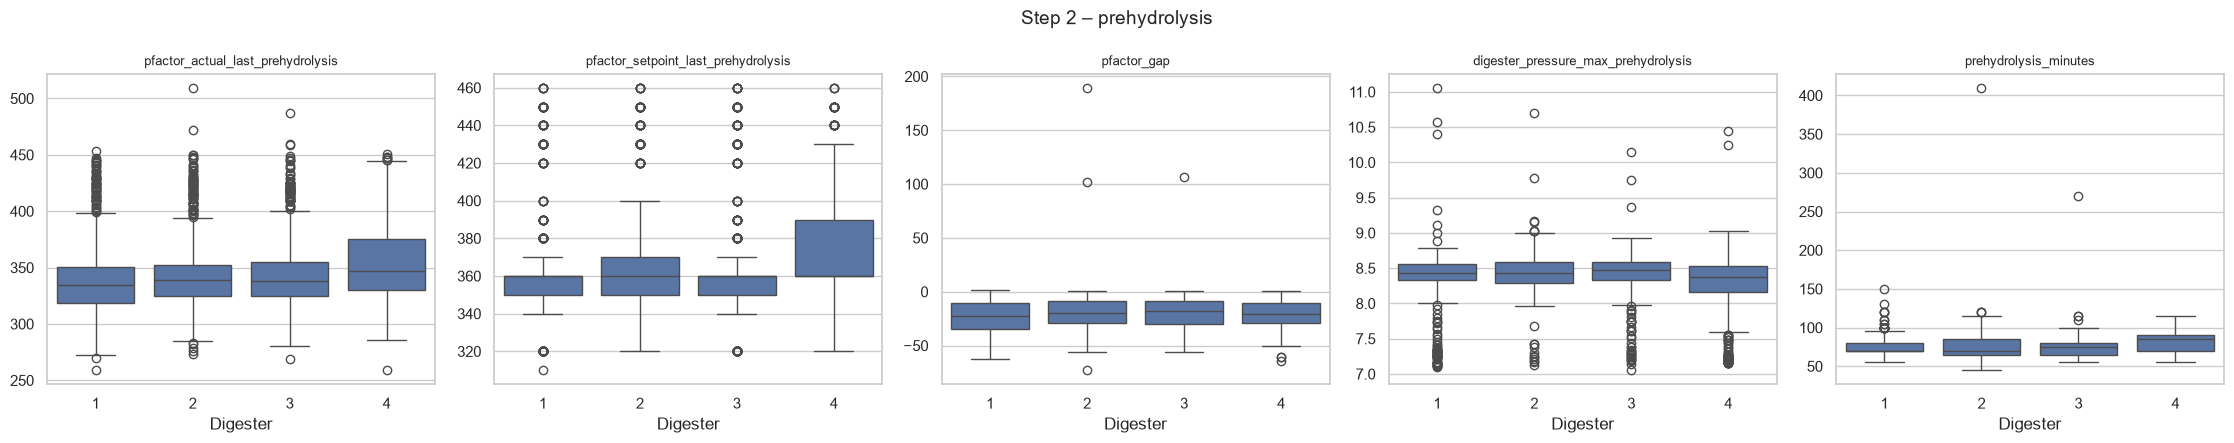

In [ ]:
STEP2 = [
         "pfactor_actual_last_prehydrolysis", 
         "pfactor_setpoint_last_prehydrolysis", 
         "pfactor_gap",
         "digester_pressure_max_prehydrolysis", 
         "prehydrolysis_minutes"]
display(volatility_table(STEP2))
boxplots(STEP2, "Step 2 – prehydrolysis")

## Step 3 – Heat & cook

- `h_factor` (phases in `config.H_FACTOR_PHASES`) and `h_heat_and_cook` (HEAT&COOK only, for comparison)
- temperatures, steam, pressure, and circulation health (screen ΔP, pump current)

N    Mean    SD  \
Parameter                                   Digester                      
circulation_temp_max_heat_and_cook          D1        841  157.51  1.43   
                                            D2        854  159.28  1.98   
                                            D3        855  158.01  1.41   
                                            D4        359  158.78  1.60   
heat_and_cook_minutes                       D1        841   35.80  5.26   
                                            D2        854   29.56  5.70   
                                            D3        855   34.70  6.00   
                                            D4        359   35.03  5.66   
steam_to_heater_flow_mean_heat_and_cook     D1        841    2.87  4.12   
                                            D2        854    2.69  1.75   
                                            D3        855    1.54  1.42   
                                            D4        359   17.59  6.11   
screen_diff_pressure_mean_heat_and_cook     D1        841   -1.87  0.00   
                                            D2        854   -0.25  0.00   
                                            D3        855   -0.25  0.00   
                                            D4          0     NaN   NaN   
circulation_pump_current_mean_heat_and_cook D1        841   65.32  4.67   
                                            D2        854   64.56  6.12   
                                            D3        855   66.91  5.23   
                                            D4        359   64.36  5.13   

                                                         CV%     Min     Max  
Parameter                                   Digester                          
circulation_temp_max_heat_and_cook          D1          0.91  153.75  163.99  
                                            D2          1.24  153.61  205.62  
                                            D3          0.89  150.99  163.36  
                                            D4          1.01  152.83  163.23  
heat_and_cook_minutes                       D1         14.69   15.00   95.00  
                                            D2         19.27   20.00  115.00  
                                            D3         17.29   15.00  100.00  
                                            D4         16.15   25.00   60.00  
steam_to_heater_flow_mean_heat_and_cook     D1        143.55   -5.87   12.32  
                                            D2         65.12   -3.25    8.51  
                                            D3         92.39   -3.14    5.14  
                                            D4         34.75   -0.13   21.03  
screen_diff_pressure_mean_heat_and_cook     D1         -0.00   -1.87   -1.87  
                                            D2         -0.00   -0.25   -0.25  
                                            D3         -1.49   -0.25   -0.19  
                                            D4           NaN     NaN     NaN  
circulation_pump_current_mean_heat_and_cook D1          7.14   47.21   75.84  
                                            D2          9.48   18.23   78.41  
                                            D3          7.81   19.52   77.90  
                                            D4          7.97   29.21   74.12

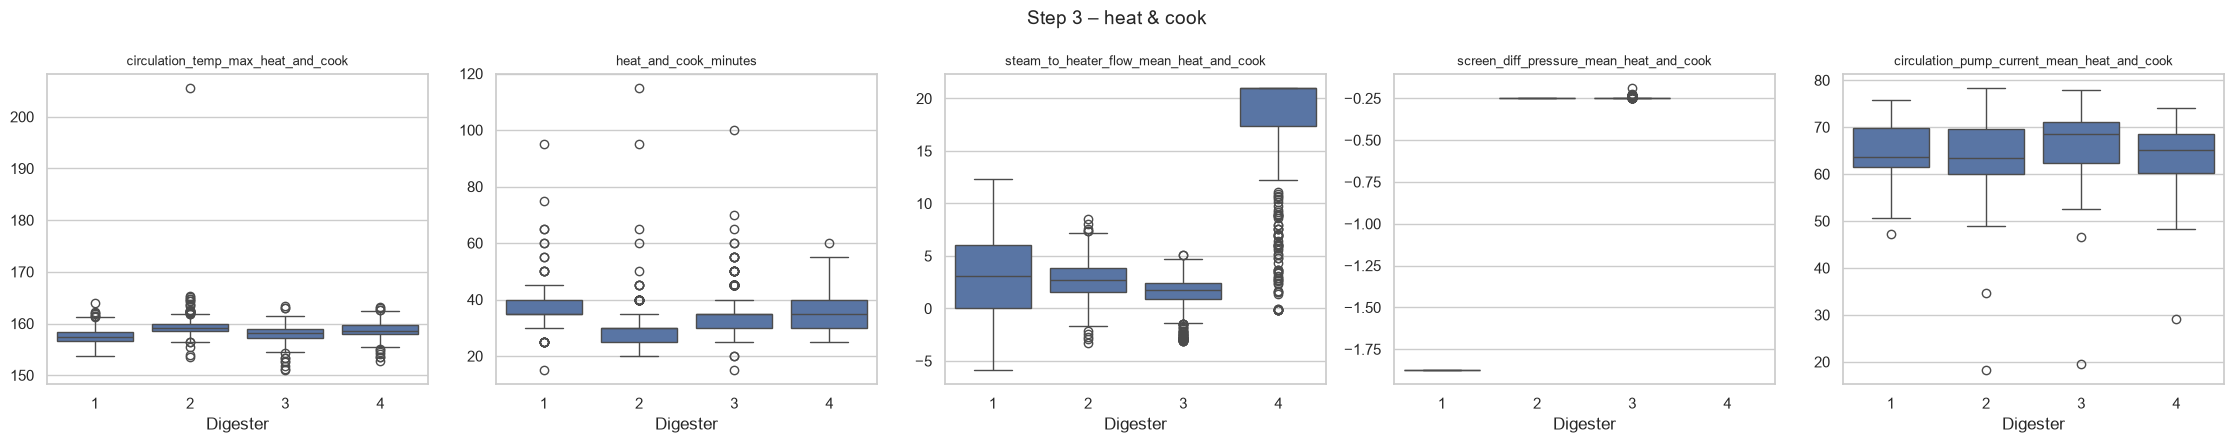

In [34]:
STEP3 = [
        # "h_factor", 
        # "h_heat_and_cook", 
         "circulation_temp_max_heat_and_cook", 
         "heat_and_cook_minutes",
         "steam_to_heater_flow_mean_heat_and_cook", 
         "screen_diff_pressure_mean_heat_and_cook",
         "circulation_pump_current_mean_heat_and_cook"]
display(volatility_table(STEP3))
boxplots(STEP3, "Step 3 – heat & cook")

## Step 4 – Displacement

- `displacement_liquor_temp_mean_displacement`, `displacement_minutes`, `h_displacement` (cooking still going on)
- `black_liquor_conductivity_mean_displacement` (shared tag, residual-alkali proxy)

N    Mean     SD  \
Parameter                                   Digester                       
displacement_liquor_temp_mean_displacement  D1        841  135.70   5.67   
                                            D2        854  133.92   6.80   
                                            D3        855  140.64   7.15   
                                            D4        359  134.96   6.28   
displacement_minutes                        D1        841   35.67  17.97   
                                            D2        854   30.80  13.34   
                                            D3        855   38.95  17.39   
                                            D4        359   36.88  22.09   
black_liquor_conductivity_mean_displacement D1        841   50.81   8.86   
                                            D2        854   51.36  12.54   
                                            D3        855   50.90  10.19   
                                            D4        359   50.53   7.69   

                                                        CV%     Min     Max  
Parameter                                   Digester                         
displacement_liquor_temp_mean_displacement  D1         4.18  111.64  151.60  
                                            D2         5.08  118.92  156.51  
                                            D3         5.09  114.61  157.12  
                                            D4         4.65  116.83  152.13  
displacement_minutes                        D1        50.39   20.00  340.00  
                                            D2        43.32   15.00  230.00  
                                            D3        44.64   15.00  350.00  
                                            D4        59.89   25.00  335.00  
black_liquor_conductivity_mean_displacement D1        17.43   48.97  125.97  
                                            D2        24.41   48.97  152.56  
                                            D3        20.01   48.97  151.53  
                                            D4        15.22   48.97  124.98

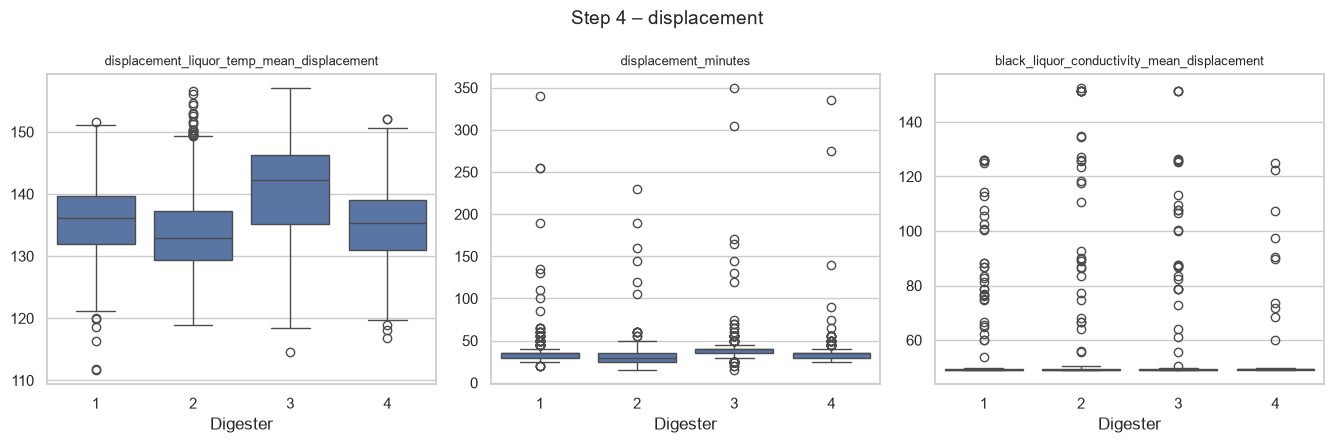

In [48]:
STEP4 = [
    "displacement_liquor_temp_mean_displacement", 
    "displacement_minutes", 
    # "h_displacement",
    "black_liquor_conductivity_mean_displacement"]
display(volatility_table(STEP4))
boxplots(STEP4, "Step 4 – displacement")

## Phase 4 – Link to lab: which batch values go with Press 1 quality?

Only batches with a lab value. Spearman correlation per digester (rows = batch values, columns = lab).
Rough guide with ~60–85 batches per digester: |r| < 0.25 is likely noise.

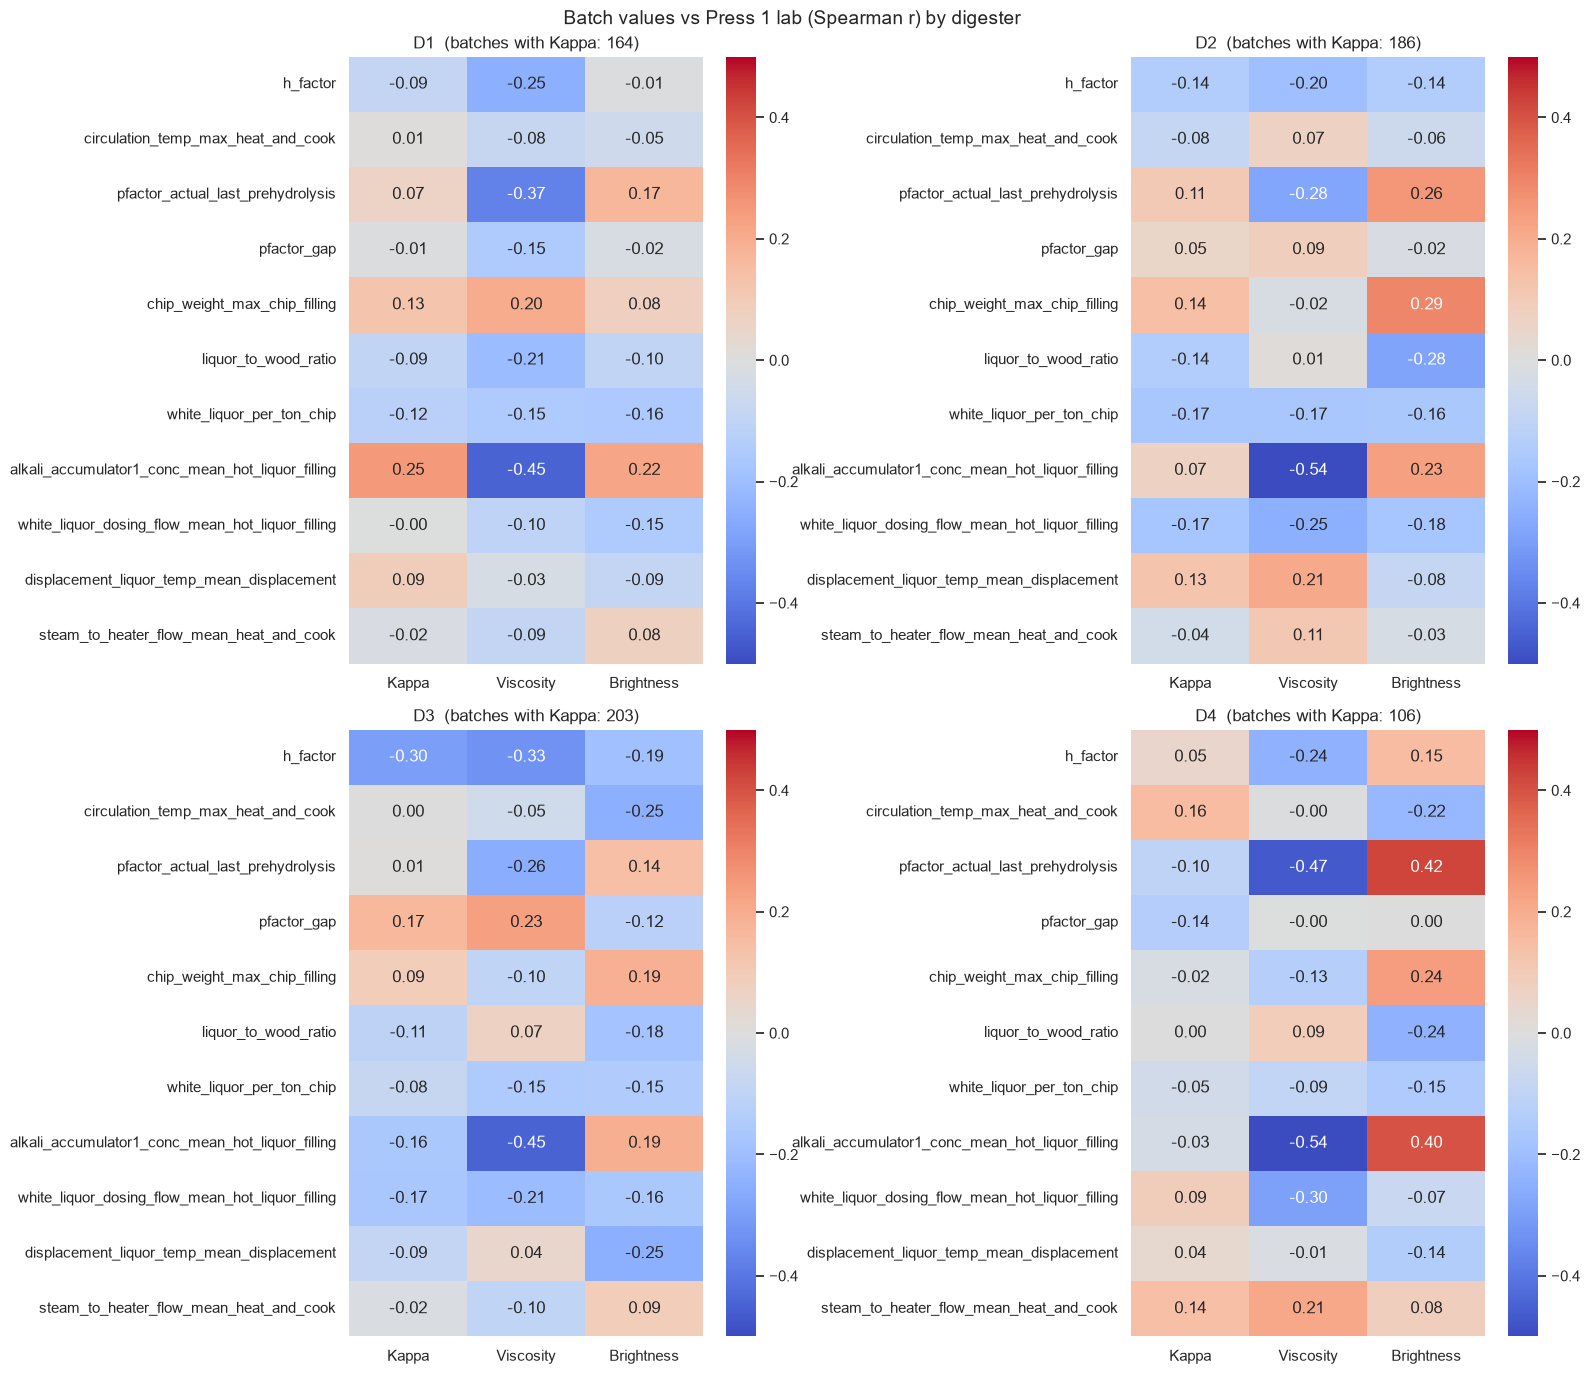

In [49]:
X_COLUMNS = ["h_factor",
             "circulation_temp_max_heat_and_cook", "pfactor_actual_last_prehydrolysis", "pfactor_gap",
             "chip_weight_max_chip_filling", "liquor_to_wood_ratio", "white_liquor_per_ton_chip",
             "alkali_accumulator1_conc_mean_hot_liquor_filling", "white_liquor_dosing_flow_mean_hot_liquor_filling",
             "displacement_liquor_temp_mean_displacement","steam_to_heater_flow_mean_heat_and_cook"]
X_COLUMNS = [c for c in X_COLUMNS if c in master]
CORR_LIMIT = 0.5

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
for ax, dig in zip(axes.flatten(), [1, 2, 3, 4]):
    d = master[master["digester"] == dig]
    corr = pd.DataFrame({label: [d[x].corr(d[param], method="spearman") for x in X_COLUMNS]
                         for param, label in LAB_LABELS.items()}, index=X_COLUMNS)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-CORR_LIMIT, vmax=CORR_LIMIT, ax=ax)
    ax.set_title(f"D{dig}  (batches with Kappa: {d['press1_kappa'].notna().sum()})")
plt.suptitle("Batch values vs Press 1 lab (Spearman r) by digester", fontsize=14)
plt.tight_layout()
plt.show()

### White liquor per ton of chips vs Kappa

H-factor uses only temperature and time – it does not see how many tons of chips are in the digester.
The white liquor volume looks like a fixed recipe, so a batch with fewer chips gets **more alkali per ton**.
Expected: dots going down to the right (more white liquor per ton → lower Kappa).

⚠️ Chip weight is **wet** (moisture tag not usable) and the white liquor tag is shared (read only while this digester is in HOT LIQUOR FILLING).
D4 is a newer digester, its volume may differ – compare D4 with itself only.


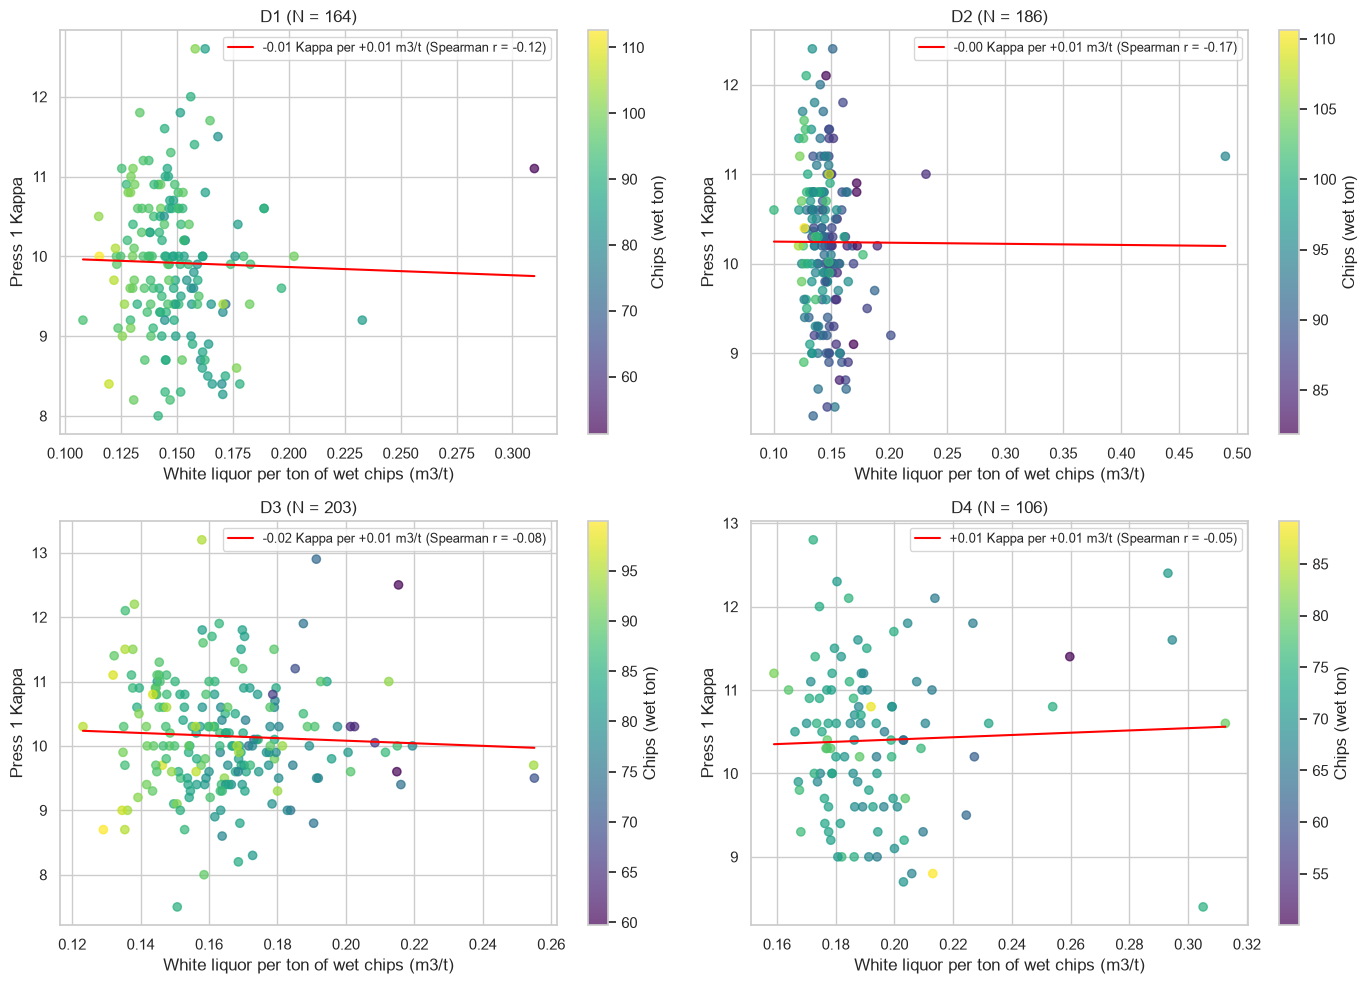

chip_weight_max_chip_filling        white_liquor_m3         \
                               median    std          median    std   
digester                                                              
1                              91.345  6.428          13.184  1.476   
2                              91.262  5.404          13.161  1.770   
3                              84.717  6.625          13.256  1.588   
4                              71.475  4.998          13.178  1.800   

         white_liquor_per_ton_chip         
                            median    std  
digester                                   
1                            0.147  0.020  
2                            0.146  0.021  
3                            0.162  0.023  
4                            0.190  0.029

digester
1   -0.03
2   -0.10
3   -0.08
4    0.00
Name: Spearman r: white liquor m3 vs chip weight (≈ 0 = not adjusted to chips), dtype: float64

In [50]:
wk = master.dropna(subset=["white_liquor_per_ton_chip", "press1_kappa"])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, dig in zip(axes.flatten(), [1, 2, 3, 4]):
    d = wk[wk["digester"] == dig]
    points = ax.scatter(d["white_liquor_per_ton_chip"], d["press1_kappa"], c=d["chip_weight_max_chip_filling"],
                        cmap="viridis", alpha=0.7)
    fig.colorbar(points, ax=ax, label="Chips (wet ton)")
    if len(d) >= 5:
        slope, intercept = np.polyfit(d["white_liquor_per_ton_chip"], d["press1_kappa"], 1)
        x = np.linspace(d["white_liquor_per_ton_chip"].min(), d["white_liquor_per_ton_chip"].max(), 50)
        r = d["white_liquor_per_ton_chip"].corr(d["press1_kappa"], method="spearman")
        ax.plot(x, slope * x + intercept, color="red",
                label=f"{slope * 0.01:+.2f} Kappa per +0.01 m3/t (Spearman r = {r:.2f})")
        ax.legend(fontsize=9)
    ax.set_title(f"D{dig} (N = {len(d)})")
    ax.set_xlabel("White liquor per ton of wet chips (m3/t)")
    ax.set_ylabel("Press 1 Kappa")
plt.tight_layout()
plt.show()

# Is the white liquor volume really fixed? (small SD = fixed recipe, not adjusted to the chip weight)
display(master.groupby("digester")[["chip_weight_max_chip_filling", "white_liquor_m3", "white_liquor_per_ton_chip"]]
        .agg(["median", "std"]).round(3))
display(master.groupby("digester").apply(
    lambda d: d["white_liquor_m3"].corr(d["chip_weight_max_chip_filling"], method="spearman"))
        .round(2).rename("Spearman r: white liquor m3 vs chip weight (≈ 0 = not adjusted to chips)"))


### Accumulator 1 alkali (`PM2.404AIC670`) vs Press 1 Viscosity – 2-sigma filtered

- X = `alkali_accumulator1_conc_mean_hot_liquor_filling`: mean g/l while **this digester** fills hot liquor (shared tag)
- Y = `press1_viscosity`: real log book samples linked to the **same batch** (not the PI-interpolated tag)
- Filter per digester: drop a batch when X **or** Y is outside mean ± `SIGMA` × SD of that digester
- Colour = batch date. ⚠️ Both values drift over Aug–Sep (alkali up, viscosity down): if the colours form separate groups, the slope is mostly a time trend, not a batch-to-batch effect.


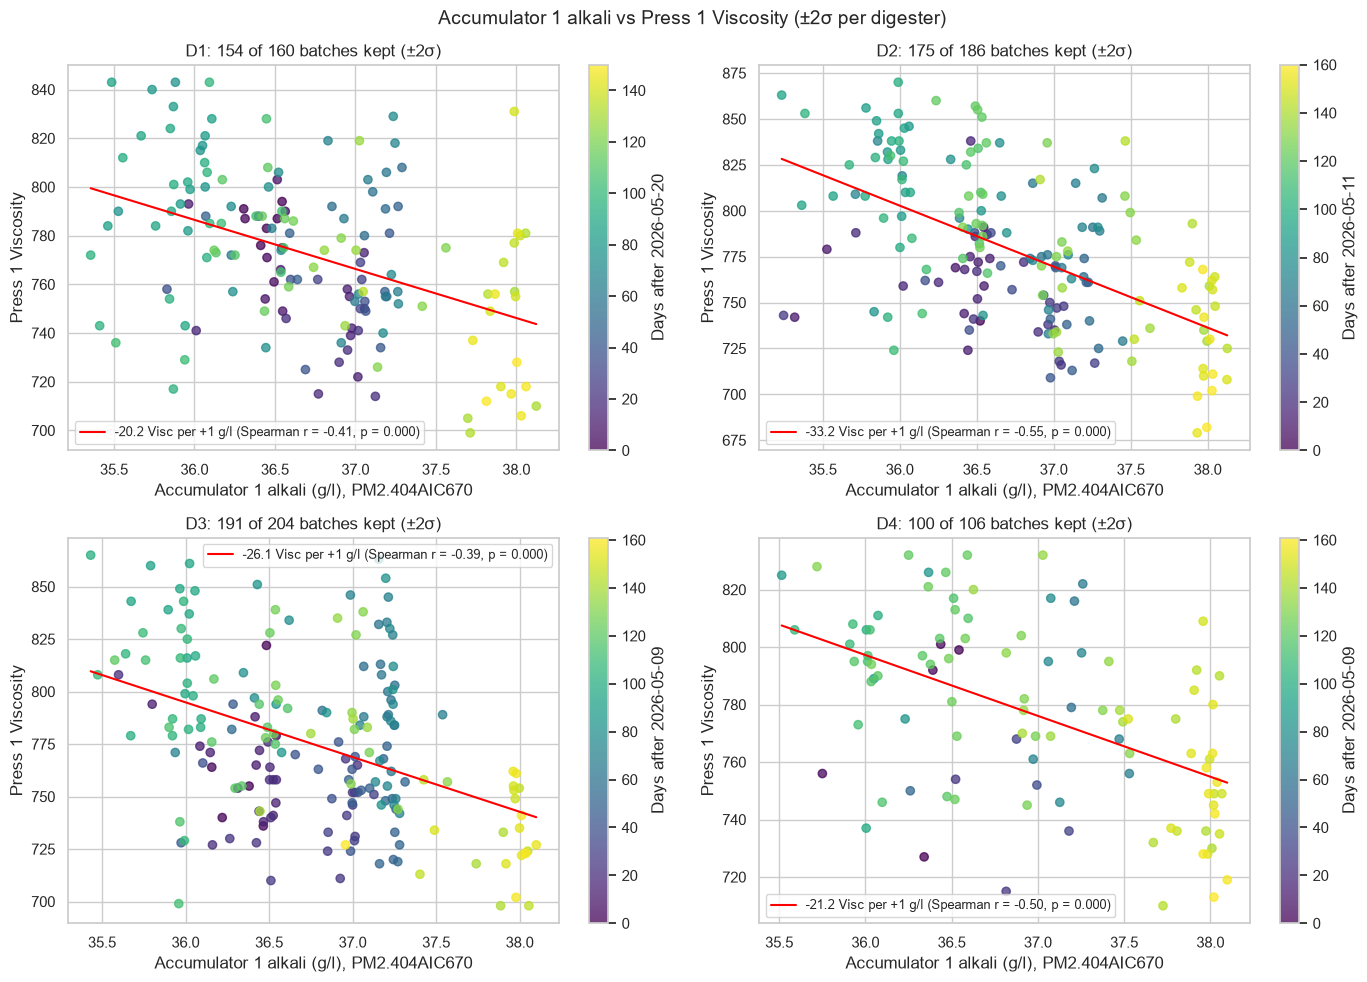

,Digester,N before,N after,Removed,X mean,Y mean,Spearman r,p-value
0,D1,160,154,6,36.717,772.032,-0.410,0.0
1,D2,186,175,11,36.755,777.709,-0.547,0.0
2,D3,204,191,13,36.788,774.351,-0.392,0.0
3,D4,106,100,6,36.961,776.900,-0.497,0.0


In [51]:
from scipy.stats import spearmanr

SIGMA = 2
X_COL, X_LABEL = "alkali_accumulator1_conc_mean_hot_liquor_filling", "Accumulator 1 alkali (g/l), PM2.404AIC670"
Y_COL, Y_LABEL = "press1_viscosity", "Press 1 Viscosity"


def within_sigma(values, sigma):
    return (values - values.mean()).abs() <= sigma * values.std()


av = master.dropna(subset=[X_COL, Y_COL])
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
rows = []
for ax, dig in zip(axes.flatten(), [1, 2, 3, 4]):
    d = av[av["digester"] == dig]
    keep = within_sigma(d[X_COL], SIGMA) & within_sigma(d[Y_COL], SIGMA)
    kept = d[keep]
    days = (kept["batch_start"] - kept["batch_start"].min()).dt.days
    points = ax.scatter(kept[X_COL], kept[Y_COL], c=days, cmap="viridis", alpha=0.75)
    fig.colorbar(points, ax=ax, label=f"Days after {kept['batch_start'].min():%Y-%m-%d}")
    r, p = spearmanr(kept[X_COL], kept[Y_COL]) if len(kept) >= 5 else (np.nan, np.nan)
    if len(kept) >= 5:
        slope, intercept = np.polyfit(kept[X_COL], kept[Y_COL], 1)
        x = np.linspace(kept[X_COL].min(), kept[X_COL].max(), 50)
        ax.plot(x, slope * x + intercept, color="red",
                label=f"{slope:+.1f} Visc per +1 g/l (Spearman r = {r:.2f}, p = {p:.3f})")
        ax.legend(fontsize=9)
    ax.set_title(f"D{dig}: {len(kept)} of {len(d)} batches kept (±{SIGMA}σ)")
    ax.set_xlabel(X_LABEL)
    ax.set_ylabel(Y_LABEL)
    rows.append({"Digester": f"D{dig}", "N before": len(d), "N after": len(kept), "Removed": len(d) - len(kept),
                 "X mean": kept[X_COL].mean(), "Y mean": kept[Y_COL].mean(), "Spearman r": r, "p-value": p})
fig.suptitle(f"Accumulator 1 alkali vs Press 1 Viscosity (±{SIGMA}σ per digester)", fontsize=14)
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows).round(3))


### P-factor vs Press 1 Viscosity, per digester

Scatter of prehydrolysis P-factor (`pfactor_actual_last_prehydrolysis`) against Press 1 Viscosity, one panel per digester. 
Same style as the alkali chart: outliers beyond ±σ on either axis are dropped, points are coloured by batch date, and the red line is an OLS fit with the Spearman r / p. 
No lag/production adjustment — a *hypothesis*, not a finding.

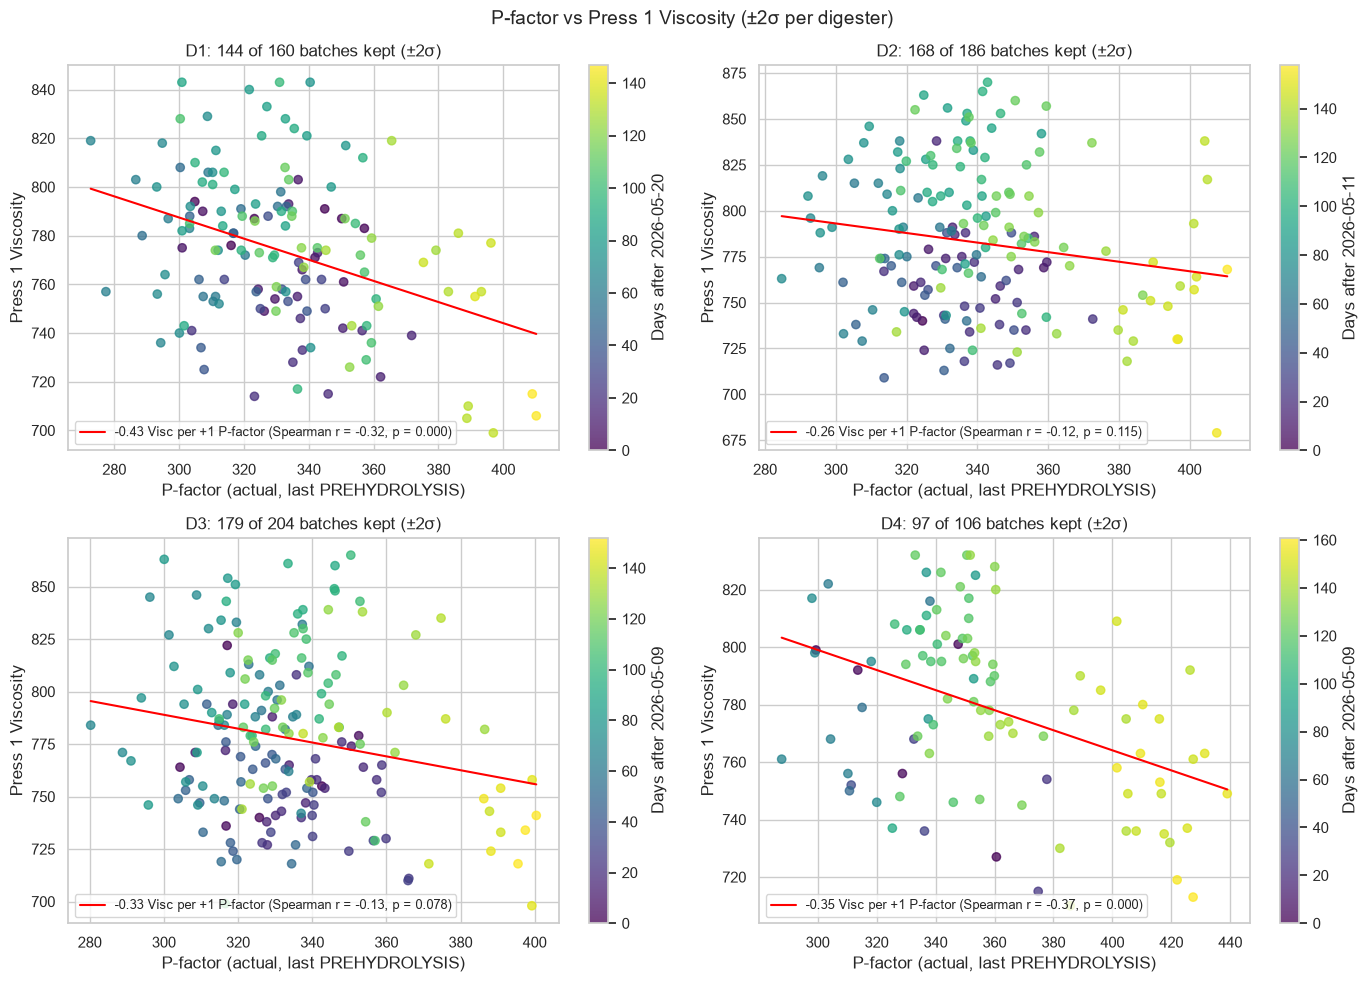

,Digester,N before,N after,Removed,X mean,Y mean,Spearman r,p-value
0,D1,160,144,16,331.865,773.618,-0.322,0.000
1,D2,186,168,18,339.947,782.673,-0.122,0.115
2,D3,204,179,25,334.088,777.704,-0.132,0.078
3,D4,106,97,9,358.557,778.557,-0.368,0.000


In [52]:
from scipy.stats import spearmanr

SIGMA = 2
X_COL, X_LABEL = "pfactor_actual_last_prehydrolysis", "P-factor (actual, last PREHYDROLYSIS)"
Y_COL, Y_LABEL = "press1_viscosity", "Press 1 Viscosity"


def within_sigma(values, sigma):
    return (values - values.mean()).abs() <= sigma * values.std()


av = master.dropna(subset=[X_COL, Y_COL])
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
rows = []
for ax, dig in zip(axes.flatten(), [1, 2, 3, 4]):
    d = av[av["digester"] == dig]
    keep = within_sigma(d[X_COL], SIGMA) & within_sigma(d[Y_COL], SIGMA)
    kept = d[keep]
    days = (kept["batch_start"] - kept["batch_start"].min()).dt.days
    points = ax.scatter(kept[X_COL], kept[Y_COL], c=days, cmap="viridis", alpha=0.75)
    fig.colorbar(points, ax=ax, label=f"Days after {kept['batch_start'].min():%Y-%m-%d}")
    r, p = spearmanr(kept[X_COL], kept[Y_COL]) if len(kept) >= 5 else (np.nan, np.nan)
    if len(kept) >= 5:
        slope, intercept = np.polyfit(kept[X_COL], kept[Y_COL], 1)
        x = np.linspace(kept[X_COL].min(), kept[X_COL].max(), 50)
        ax.plot(x, slope * x + intercept, color="red",
                label=f"{slope:+.2f} Visc per +1 P-factor (Spearman r = {r:.2f}, p = {p:.3f})")
        ax.legend(fontsize=9)
    ax.set_title(f"D{dig}: {len(kept)} of {len(d)} batches kept (±{SIGMA}σ)")
    ax.set_xlabel(X_LABEL)
    ax.set_ylabel(Y_LABEL)
    rows.append({"Digester": f"D{dig}", "N before": len(d), "N after": len(kept), "Removed": len(d) - len(kept),
                 "X mean": kept[X_COL].mean(), "Y mean": kept[Y_COL].mean(), "Spearman r": r, "p-value": p})
fig.suptitle(f"P-factor vs Press 1 Viscosity (±{SIGMA}σ per digester)", fontsize=14)
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows).round(3))

# Golden Batch analysis (Golden vs Non-Golden)

Golden is **defined from Y (lab quality)**, not from a process cut. We reuse the existing `overall_grade` column from `build_master` (bands: Kappa 8-10, Viscosity 700-800 - *unconfirmed with process team*):

- **Golden** = `overall_grade == "normal"` (both Kappa **and** Viscosity inside band)
- **Non-Golden** = `overall_grade == "abnormal"` (at least one off-band)
- batches missing a lab result are dropped (never judged on partial data)

Scope = **pooled across D1-D4** (per-digester n is too small), with `digester` kept only as a split-check.

Four views, in order:
1. split counts (Golden vs Non-Golden), overall and per digester
2. **Mean + Variance** of each X: Golden vs Non-Golden, with mean diff, Mann-Whitney U *p*, Cliff's delta
3. **Spearman** of each X vs each Y (Kappa, Viscosity) - pooled
4. **Distribution** of each X in Golden vs Non-Golden (overlaid) + Golden p10-p90 window

> Caveats (project rules): N = batches with a real lab sample (Kappa every ~4 h), not interpolated points. Correlations are **hypotheses**, not findings. The grade bands are not yet confirmed by the process team.


In [53]:
from scipy.stats import mannwhitneyu, spearmanr

# Golden is defined from Y via the existing overall_grade column (normal / abnormal).
GOLDEN_COL = "overall_grade"

# X parameters to profile: union of the Step 1-4 lists already defined above.
GOLDEN_X = []
for _lst in (STEP1, STEP2, STEP3, STEP4):
    for _c in _lst:
        if _c in master.columns and _c not in GOLDEN_X:
            GOLDEN_X.append(_c)

# split (drop batches with no lab -> overall_grade is NaN)
graded = master[master[GOLDEN_COL].notna()].copy()
golden = graded[graded[GOLDEN_COL] == "normal"]
nongolden = graded[graded[GOLDEN_COL] == "abnormal"]

print(f"Graded batches: {len(graded)}  |  Golden: {len(golden)}  |  Non-Golden: {len(nongolden)}")
print(f"X parameters profiled: {len(GOLDEN_X)}")

# split-check per digester (make sure Golden is not just one digester)
split = (graded.groupby("digester")[GOLDEN_COL]
         .value_counts().unstack(fill_value=0)
         .reindex(columns=["normal", "abnormal"], fill_value=0)
         .rename(columns={"normal": "Golden", "abnormal": "Non-Golden"}))
split["Golden %"] = (100 * split["Golden"] / (split["Golden"] + split["Non-Golden"])).round(1)
split.index = [f"D{int(i)}" for i in split.index]
display(split)


Graded batches: 654  |  Golden: 251  |  Non-Golden: 403
X parameters profiled: 19


overall_grade,Golden,Non-Golden,Golden %
D1,83,77,51.9
D2,55,131,29.6
D3,85,117,42.1
D4,28,78,26.4


In [54]:
def cliffs_delta(a, b):
    """Cliff's delta effect size in [-1, 1]; |d|: .11 small, .28 medium, .43 large."""
    a, b = np.asarray(a), np.asarray(b)
    if len(a) == 0 or len(b) == 0:
        return np.nan
    gt = sum((a[:, None] > b[None, :]).sum(axis=1))
    lt = sum((a[:, None] < b[None, :]).sum(axis=1))
    return (gt - lt) / (len(a) * len(b))


def golden_compare(params=GOLDEN_X):
    """Mean + Variance (SD) of each X in Golden vs Non-Golden, with effect size and MWU p."""
    rows = []
    for p in params:
        g = golden[p].dropna()
        ng = nongolden[p].dropna()
        if len(g) < MIN_N or len(ng) < MIN_N:
            continue
        try:
            _, pval = mannwhitneyu(g, ng, alternative="two-sided")
        except ValueError:
            pval = np.nan
        rows.append({
            "Parameter": p,
            "N_gold": len(g), "N_non": len(ng),
            "Mean_gold": g.mean(), "Mean_non": ng.mean(),
            "SD_gold": g.std(), "SD_non": ng.std(),
            "MeanDiff": g.mean() - ng.mean(),
            "Cliffs_d": cliffs_delta(g, ng),
            "MWU_p": pval,
        })
    out = pd.DataFrame(rows).set_index("Parameter")
    out["abs_d"] = out["Cliffs_d"].abs()
    out = out.sort_values("abs_d", ascending=False).drop(columns="abs_d")
    return out.round(3)


golden_cmp = golden_compare()
print("Sorted by |Cliff's delta| (separation between Golden and Non-Golden). "
      "|d|: .11 small, .28 medium, .43 large. MWU_p is a hypothesis, not proof.")
display(golden_cmp)


Sorted by |Cliff's delta| (separation between Golden and Non-Golden). |d|: .11 small, .28 medium, .43 large. MWU_p is a hypothesis, not proof.


,N_gold,N_non,Mean_gold,Mean_non,SD_gold,SD_non,MeanDiff,Cliffs_d,MWU_p
Parameter,,,,,,,,,
black_liquor_conductivity_mean_displacement,251,403,51.871,51.514,12.174,11.864,0.357,-0.327,0.000
prehydrolysis_minutes,251,403,75.578,81.154,9.837,19.591,-5.576,-0.278,0.000
ventilation_temp_max_chip_filling,251,403,90.743,91.619,1.951,3.138,-0.876,-0.249,0.000
digester_pressure_max_prehydrolysis,251,403,8.394,8.282,0.383,0.401,0.111,0.203,0.000
liquor_to_wood_ratio,251,403,1.677,1.610,0.238,0.241,0.067,0.192,0.000
white_liquor_m3,251,403,13.735,13.731,1.291,2.342,0.004,0.145,0.002
displacement_minutes,251,403,35.558,34.864,13.765,15.879,0.694,0.117,0.010
screen_diff_pressure_mean_heat_and_cook,223,325,-0.855,-0.635,0.787,0.692,-0.220,-0.115,0.004
displacement_liquor_temp_mean_displacement,251,403,136.355,135.161,7.237,6.613,1.194,0.105,0.023


Spearman of each X vs Y (pooled, graded batches). Hypotheses only - no lag/production adjustment.


,Kappa_rho,Kappa_p,Kappa_n,Viscosity_rho,Viscosity_p,Viscosity_n
Parameter,,,,,,
pfactor_setpoint_last_prehydrolysis,0.044,0.263,654,-0.356,0.000,654
black_liquor_conductivity_mean_displacement,0.193,0.000,654,0.341,0.000,654
pfactor_actual_last_prehydrolysis,0.069,0.079,654,-0.299,0.000,654
digester_pressure_max_prehydrolysis,-0.104,0.008,654,-0.260,0.000,654
white_liquor_m3,-0.090,0.021,654,-0.243,0.000,654
heat_and_cook_minutes,-0.008,0.840,654,-0.212,0.000,654
prehydrolysis_minutes,0.187,0.000,654,0.137,0.000,654
displacement_minutes,-0.099,0.011,654,-0.172,0.000,654
ventilation_temp_max_chip_filling,0.158,0.000,654,0.130,0.001,654


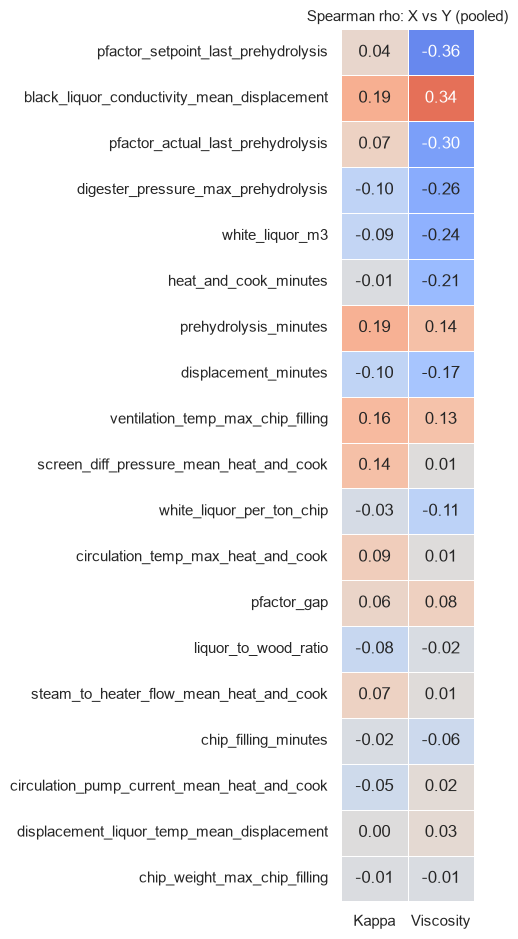

In [55]:
GOLDEN_Y = ["press1_kappa", "press1_viscosity"]   # Y targets that define the grade


def spearman_xy(params=GOLDEN_X, ys=GOLDEN_Y, data=graded):
    """Spearman rho (and p) of each X vs each Y, pooled over all graded batches."""
    rows = []
    for p in params:
        row = {"Parameter": p}
        for y in ys:
            pair = data[[p, y]].dropna()
            if len(pair) >= MIN_N:
                rho, pval = spearmanr(pair[p], pair[y])
                row[f"{LAB_LABELS[y]}_rho"] = rho
                row[f"{LAB_LABELS[y]}_p"] = pval
                row[f"{LAB_LABELS[y]}_n"] = len(pair)
            else:
                row[f"{LAB_LABELS[y]}_rho"] = np.nan
                row[f"{LAB_LABELS[y]}_p"] = np.nan
                row[f"{LAB_LABELS[y]}_n"] = len(pair)
        rows.append(row)
    out = pd.DataFrame(rows).set_index("Parameter")
    # sort by the strongest |rho| across the Y targets
    rho_cols = [c for c in out.columns if c.endswith("_rho")]
    out["_max_abs"] = out[rho_cols].abs().max(axis=1)
    out = out.sort_values("_max_abs", ascending=False).drop(columns="_max_abs")
    return out.round(3)


spearman_tbl = spearman_xy()
print("Spearman of each X vs Y (pooled, graded batches). Hypotheses only - no lag/production adjustment.")
display(spearman_tbl)

# heatmap of rho
rho_only = spearman_tbl[[c for c in spearman_tbl.columns if c.endswith("_rho")]]
rho_only.columns = [c.replace("_rho", "") for c in rho_only.columns]
fig, ax = plt.subplots(figsize=(5, 0.45 * len(rho_only) + 1))
sns.heatmap(rho_only, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-0.5, vmax=0.5, linewidths=0.5, cbar=False, ax=ax)
ax.set_title("Spearman rho: X vs Y (pooled)", fontsize=11)
ax.set_ylabel("")
plt.tight_layout()
plt.show()


Golden p10-p90 window per X (candidate operating range, NOT a confirmed SOP).


,N,p10,median,p90,Non-Golden median
Parameter,,,,,
chip_weight_max_chip_filling,251,73.22,87.46,96.20,88.65
liquor_to_wood_ratio,251,1.42,1.64,1.98,1.57
white_liquor_m3,251,12.83,13.25,14.99,13.03
white_liquor_per_ton_chip,251,0.14,0.16,0.19,0.15
ventilation_temp_max_chip_filling,251,89.50,90.00,93.83,90.77
chip_filling_minutes,251,30.00,35.00,35.00,35.00
pfactor_actual_last_prehydrolysis,251,310.50,336.23,418.39,338.40
pfactor_setpoint_last_prehydrolysis,251,340.00,360.00,440.00,360.00
pfactor_gap,251,-39.85,-22.94,-3.51,-19.42


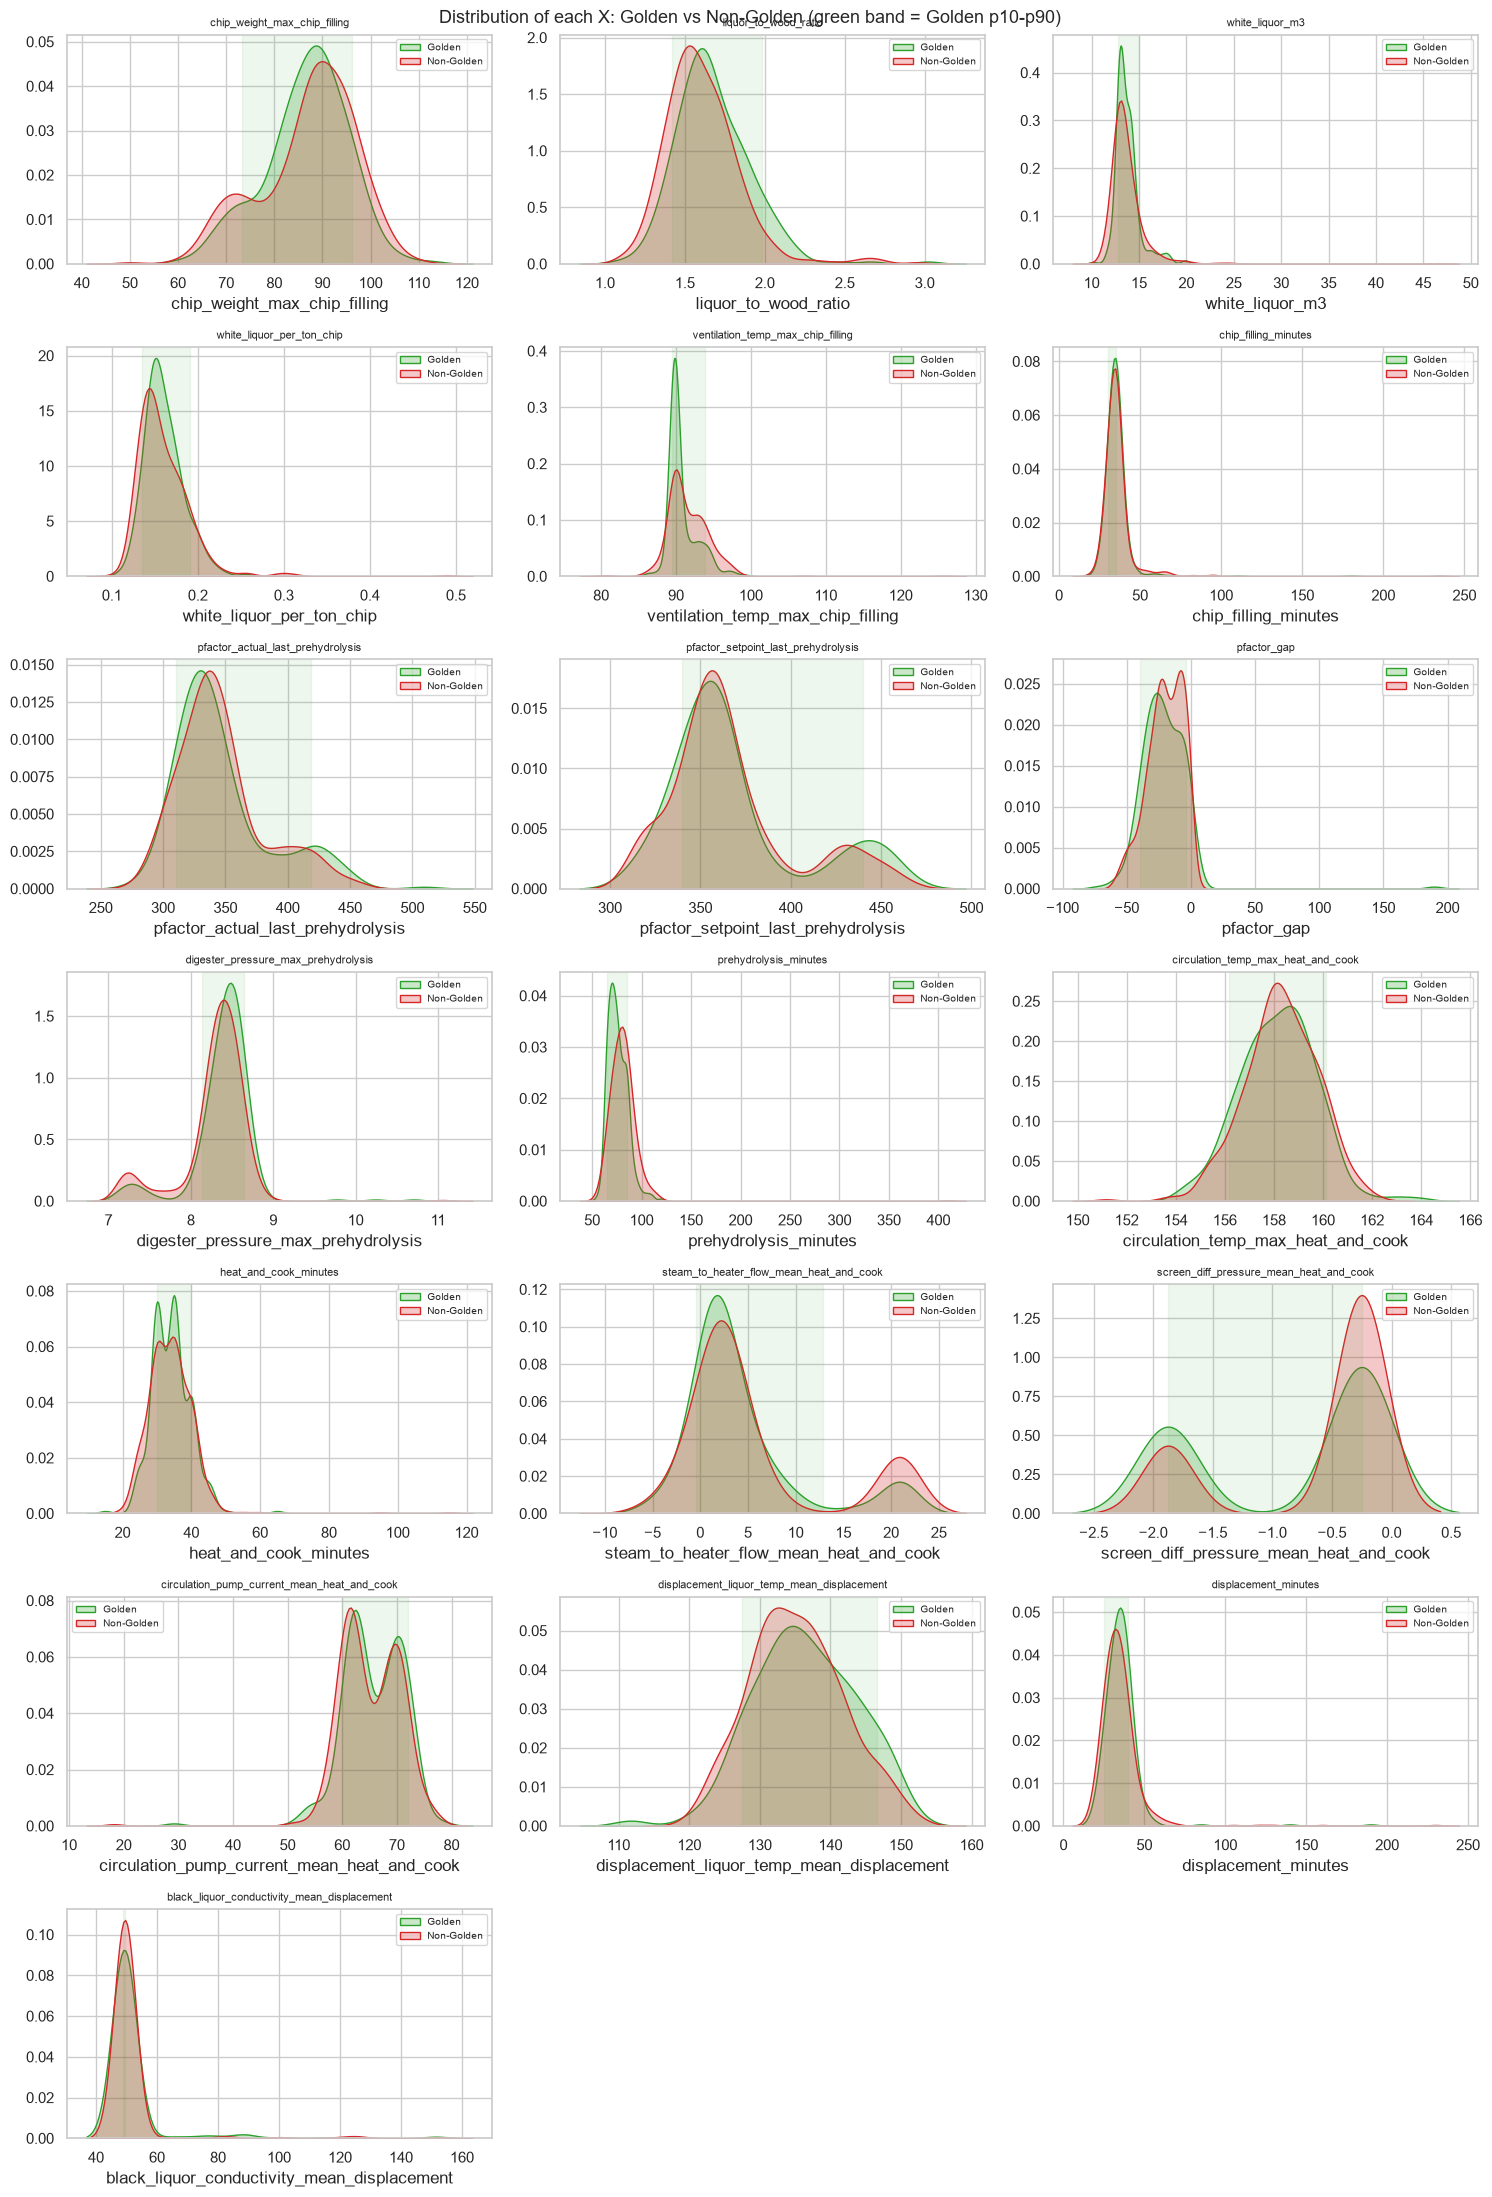

In [56]:
def golden_window(params=GOLDEN_X):
    """p10-p90 of each X within Golden batches - a candidate operating window (not an SOP)."""
    rows = []
    for p in params:
        g = golden[p].dropna()
        if len(g) < MIN_N:
            continue
        rows.append({"Parameter": p, "N": len(g),
                     "p10": g.quantile(.10), "median": g.median(), "p90": g.quantile(.90),
                     "Non-Golden median": nongolden[p].dropna().median()})
    return pd.DataFrame(rows).set_index("Parameter").round(2)


window = golden_window()
print("Golden p10-p90 window per X (candidate operating range, NOT a confirmed SOP).")
display(window)

# overlaid distributions: Golden vs Non-Golden
cols = [p for p in GOLDEN_X if golden[p].dropna().shape[0] >= MIN_N]
ncol = 3
nrow = int(np.ceil(len(cols) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 3.2 * nrow))
for ax, p in zip(axes.ravel(), cols):
    g = golden[p].dropna()
    ng = nongolden[p].dropna()
    sns.kdeplot(g, ax=ax, fill=True, color="#2ca02c", label="Golden", warn_singular=False)
    sns.kdeplot(ng, ax=ax, fill=True, color="#d62728", label="Non-Golden", warn_singular=False)
    ax.axvspan(g.quantile(.10), g.quantile(.90), color="#2ca02c", alpha=0.08)
    ax.set_title(p, fontsize=8)
    ax.set_ylabel("")
    ax.legend(fontsize=7)
for ax in axes.ravel()[len(cols):]:
    ax.set_visible(False)
fig.suptitle("Distribution of each X: Golden vs Non-Golden (green band = Golden p10-p90)", fontsize=13)
plt.tight_layout()
plt.show()


## Golden vs Non-Golden, split by digester

Same Golden definition (`overall_grade`), but now **per digester** instead of pooled. Uses all 22 Step 1-4 X parameters.

> **Caveat:** per-digester n is small, especially the Golden side (D1 83, D2 55, D3 85, **D4 only 28**). Per-digester Cliff's delta / Mann-Whitney / Spearman are noisy - treat them as *weaker* hypotheses than the pooled view above, and look for effects that repeat across several digesters rather than one.

In [61]:
def golden_compare_dig(dig, params=GOLDEN_X):
    """Mean + Variance of each X in Golden vs Non-Golden for ONE digester."""
    g_all = graded[graded["digester"] == dig]
    g = g_all[g_all[GOLDEN_COL] == "normal"]
    ng = g_all[g_all[GOLDEN_COL] == "abnormal"]
    rows = []
    for p in params:
        gp, ngp = g[p].dropna(), ng[p].dropna()
        if len(gp) < MIN_N or len(ngp) < MIN_N:
            continue
        try:
            _, pval = mannwhitneyu(gp, ngp, alternative="two-sided")
        except ValueError:
            pval = np.nan
        rows.append({"Parameter": p,
                     "Mean_gold": gp.mean(), "Mean_non": ngp.mean(),
                     "SD_gold": gp.std(), "SD_non": ngp.std(),
                     "MeanDiff": gp.mean() - ngp.mean(),
                     "Cliffs_d": cliffs_delta(gp, ngp), "MWU_p": pval})
    if not rows:
        return pd.DataFrame()
    out = pd.DataFrame(rows).set_index("Parameter")
    out["abs_d"] = out["Cliffs_d"].abs()
    return out.sort_values("abs_d", ascending=False).drop(columns="abs_d").round(3)


for dig in sorted(graded["digester"].dropna().unique()):
    n_g = int(((graded["digester"] == dig) & (graded[GOLDEN_COL] == "normal")).sum())
    n_ng = int(((graded["digester"] == dig) & (graded[GOLDEN_COL] == "abnormal")).sum())
    print(f"\n=== D{int(dig)} — Golden vs Non-Golden (Golden n={n_g}, Non-Golden n={n_ng}) ===")
    display(golden_compare_dig(dig))



=== D1 — Golden vs Non-Golden (Golden n=83, Non-Golden n=77) ===


,Mean_gold,Mean_non,SD_gold,SD_non,MeanDiff,Cliffs_d,MWU_p
Parameter,,,,,,,
chip_weight_max_chip_filling,90.808,93.556,6.316,4.937,-2.747,-0.295,0.001
liquor_to_wood_ratio,1.584,1.508,0.181,0.134,0.077,0.279,0.002
white_liquor_per_ton_chip,0.151,0.145,0.019,0.015,0.006,0.236,0.010
black_liquor_conductivity_mean_displacement,51.601,51.273,9.730,10.531,0.328,-0.158,0.070
digester_pressure_max_prehydrolysis,8.295,8.367,0.375,0.503,-0.072,-0.153,0.095
white_liquor_m3,13.679,13.547,1.503,1.412,0.132,0.117,0.201
heat_and_cook_minutes,35.904,36.364,6.005,4.026,-0.460,-0.097,0.261
pfactor_gap,-23.141,-25.933,14.997,16.333,2.792,0.092,0.319
displacement_minutes,36.325,35.584,18.612,13.644,0.741,0.079,0.360



=== D2 — Golden vs Non-Golden (Golden n=55, Non-Golden n=131) ===


,Mean_gold,Mean_non,SD_gold,SD_non,MeanDiff,Cliffs_d,MWU_p
Parameter,,,,,,,
digester_pressure_max_prehydrolysis,8.521,8.328,0.452,0.271,0.192,0.403,0.000
black_liquor_conductivity_mean_displacement,55.148,51.780,20.728,14.193,3.367,-0.345,0.000
ventilation_temp_max_chip_filling,91.770,93.111,2.398,2.609,-1.341,-0.322,0.000
white_liquor_per_ton_chip,0.148,0.146,0.014,0.034,0.002,0.252,0.007
white_liquor_m3,13.518,13.565,1.033,3.146,-0.046,0.246,0.008
prehydrolysis_minutes,76.455,82.786,12.386,30.679,-6.332,-0.243,0.008
liquor_to_wood_ratio,1.538,1.489,0.131,0.147,0.049,0.205,0.027
chip_weight_max_chip_filling,91.641,93.423,5.072,5.661,-1.781,-0.197,0.034
displacement_liquor_temp_mean_displacement,130.895,132.233,4.497,4.884,-1.338,-0.144,0.123



=== D3 — Golden vs Non-Golden (Golden n=85, Non-Golden n=117) ===


,Mean_gold,Mean_non,SD_gold,SD_non,MeanDiff,Cliffs_d,MWU_p
Parameter,,,,,,,
black_liquor_conductivity_mean_displacement,50.557,51.365,7.541,9.808,-0.808,-0.508,0.000
prehydrolysis_minutes,73.235,79.658,6.931,9.232,-6.423,-0.430,0.000
ventilation_temp_max_chip_filling,90.427,91.877,1.848,4.255,-1.450,-0.355,0.000
digester_pressure_max_prehydrolysis,8.436,8.300,0.218,0.334,0.136,0.299,0.000
pfactor_gap,-23.266,-17.843,11.503,13.762,-5.423,-0.270,0.001
displacement_minutes,38.176,36.838,4.071,11.017,1.339,0.224,0.004
displacement_liquor_temp_mean_displacement,141.177,138.717,6.118,7.368,2.460,0.196,0.018
white_liquor_m3,14.046,13.820,1.314,1.685,0.226,0.178,0.031
liquor_to_wood_ratio,1.861,1.827,0.231,0.257,0.034,0.158,0.055



=== D4 — Golden vs Non-Golden (Golden n=28, Non-Golden n=78) ===


,Mean_gold,Mean_non,SD_gold,SD_non,MeanDiff,Cliffs_d,MWU_p
Parameter,,,,,,,
liquor_to_wood_ratio,1.666,1.587,0.227,0.206,0.080,0.224,0.080
digester_pressure_max_prehydrolysis,8.306,8.095,0.547,0.501,0.211,0.201,0.115
black_liquor_conductivity_mean_displacement,50.222,51.530,4.262,11.838,-1.308,-0.185,0.063
chip_weight_max_chip_filling,70.709,72.050,3.174,5.414,-1.341,-0.174,0.174
circulation_pump_current_mean_heat_and_cook,64.784,64.130,8.214,4.446,0.653,0.169,0.186
pfactor_setpoint_last_prehydrolysis,391.786,379.615,42.431,36.125,12.170,0.162,0.195
prehydrolysis_minutes,81.786,86.282,11.239,11.437,-4.496,-0.160,0.206
pfactor_actual_last_prehydrolysis,372.332,360.338,44.315,37.570,11.994,0.147,0.250
displacement_liquor_temp_mean_displacement,136.647,134.949,7.799,6.087,1.699,0.132,0.304


Cliff's delta per X per digester (Golden - Non-Golden). Look for rows that stay the SAME sign across digesters = a repeatable hypothesis.


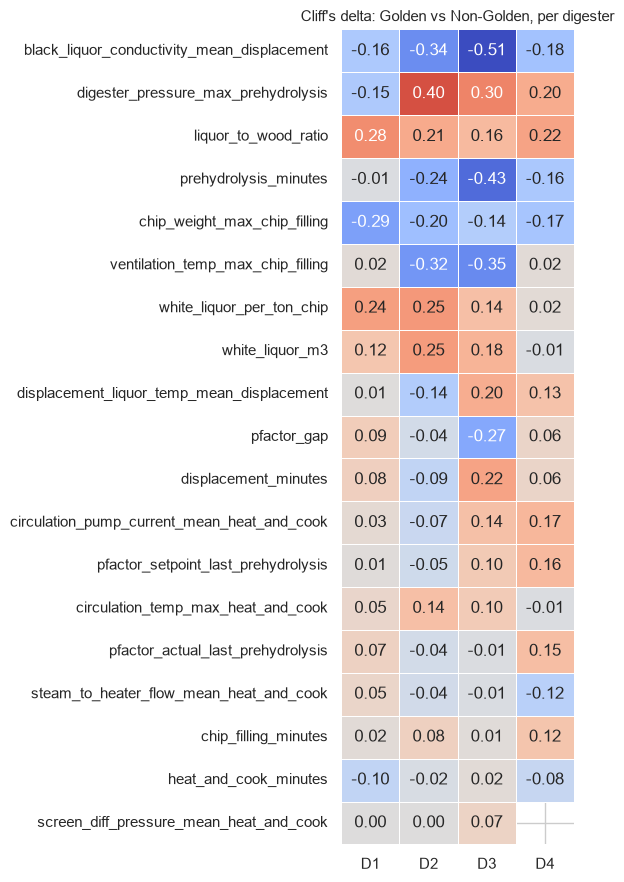

In [58]:
def cliffs_by_digester(params=GOLDEN_X):
    """Cliff's delta (Golden vs Non-Golden) for each X, one column per digester."""
    digs = sorted(graded["digester"].dropna().unique())
    out = pd.DataFrame(index=params, columns=[f"D{int(d)}" for d in digs], dtype=float)
    for d in digs:
        sub = graded[graded["digester"] == d]
        g = sub[sub[GOLDEN_COL] == "normal"]
        ng = sub[sub[GOLDEN_COL] == "abnormal"]
        for p in params:
            gp, ngp = g[p].dropna(), ng[p].dropna()
            if len(gp) >= MIN_N and len(ngp) >= MIN_N:
                out.loc[p, f"D{int(d)}"] = cliffs_delta(gp, ngp)
    # order rows by mean |delta| across digesters (strongest / most consistent on top)
    out = out.loc[out.abs().mean(axis=1).sort_values(ascending=False).index]
    return out.astype(float)


cliff_dig = cliffs_by_digester()
print("Cliff's delta per X per digester (Golden - Non-Golden). "
      "Look for rows that stay the SAME sign across digesters = a repeatable hypothesis.")
fig, ax = plt.subplots(figsize=(6, 0.42 * len(cliff_dig) + 1))
sns.heatmap(cliff_dig, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-0.5, vmax=0.5, linewidths=0.5, cbar=False, ax=ax)
ax.set_title("Cliff's delta: Golden vs Non-Golden, per digester", fontsize=11)
ax.set_ylabel("")
plt.tight_layout()
plt.show()


C:\Users\chinnput\AppData\Local\Temp\6\ipykernel_77820\1958400553.py:10: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  out.loc[p, f"D{int(d)}"] = spearmanr(pair[p], pair[y])[0]
C:\Users\chinnput\AppData\Local\Temp\6\ipykernel_77820\1958400553.py:10: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  out.loc[p, f"D{int(d)}"] = spearmanr(pair[p], pair[y])[0]



Spearman rho: X vs Kappa, per digester (hypotheses; small n per digester).


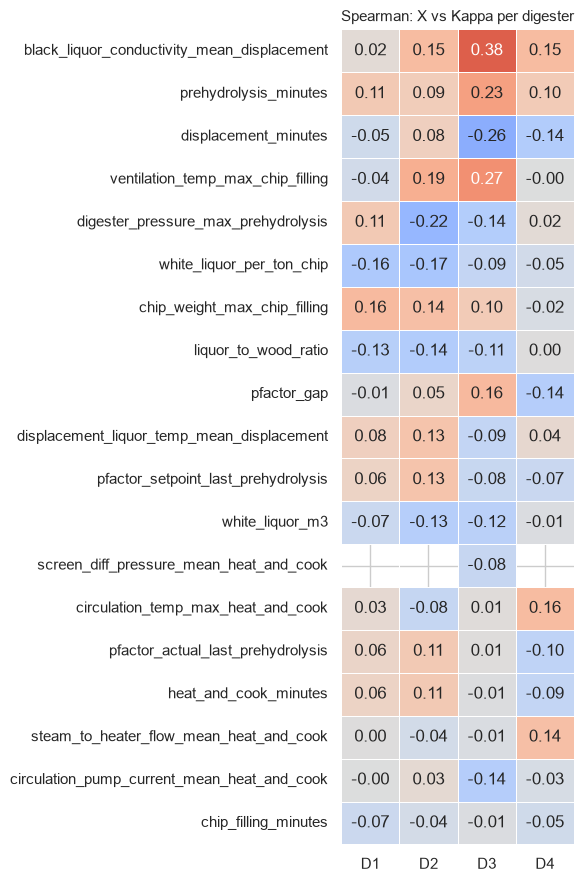

C:\Users\chinnput\AppData\Local\Temp\6\ipykernel_77820\1958400553.py:10: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  out.loc[p, f"D{int(d)}"] = spearmanr(pair[p], pair[y])[0]
C:\Users\chinnput\AppData\Local\Temp\6\ipykernel_77820\1958400553.py:10: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  out.loc[p, f"D{int(d)}"] = spearmanr(pair[p], pair[y])[0]



Spearman rho: X vs Viscosity, per digester (hypotheses; small n per digester).


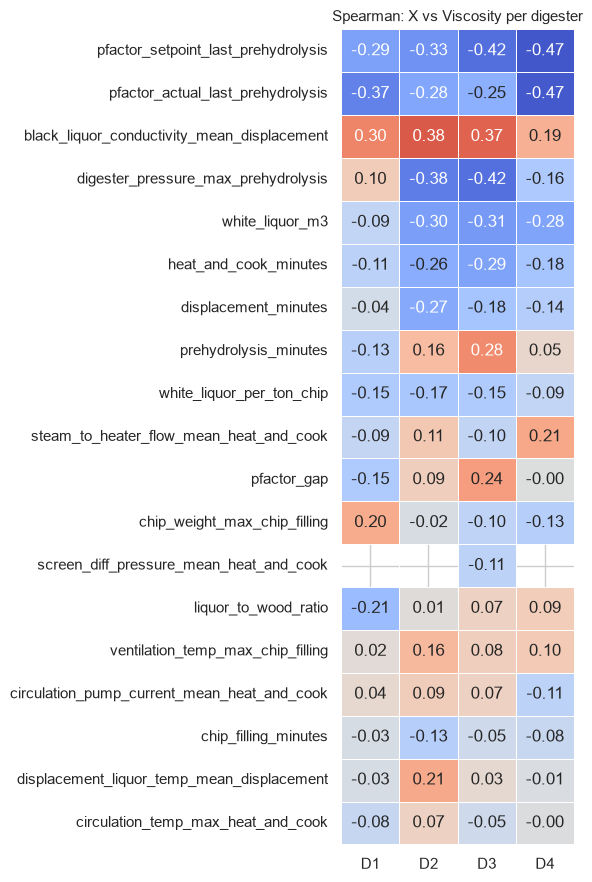

In [59]:
def spearman_by_digester(y, params=GOLDEN_X):
    """Spearman rho of each X vs one Y, one column per digester (graded batches)."""
    digs = sorted(graded["digester"].dropna().unique())
    out = pd.DataFrame(index=params, columns=[f"D{int(d)}" for d in digs], dtype=float)
    for d in digs:
        sub = graded[graded["digester"] == d]
        for p in params:
            pair = sub[[p, y]].dropna()
            if len(pair) >= MIN_N:
                out.loc[p, f"D{int(d)}"] = spearmanr(pair[p], pair[y])[0]
    return out.astype(float)


for y in GOLDEN_Y:
    tbl = spearman_by_digester(y)
    tbl = tbl.loc[tbl.abs().mean(axis=1).sort_values(ascending=False).index]
    print(f"\nSpearman rho: X vs {LAB_LABELS[y]}, per digester (hypotheses; small n per digester).")
    fig, ax = plt.subplots(figsize=(6, 0.42 * len(tbl) + 1))
    sns.heatmap(tbl, annot=True, fmt=".2f", cmap="coolwarm", center=0,
                vmin=-0.5, vmax=0.5, linewidths=0.5, cbar=False, ax=ax)
    ax.set_title(f"Spearman: X vs {LAB_LABELS[y]} per digester", fontsize=11)
    ax.set_ylabel("")
    plt.tight_layout()
    plt.show()


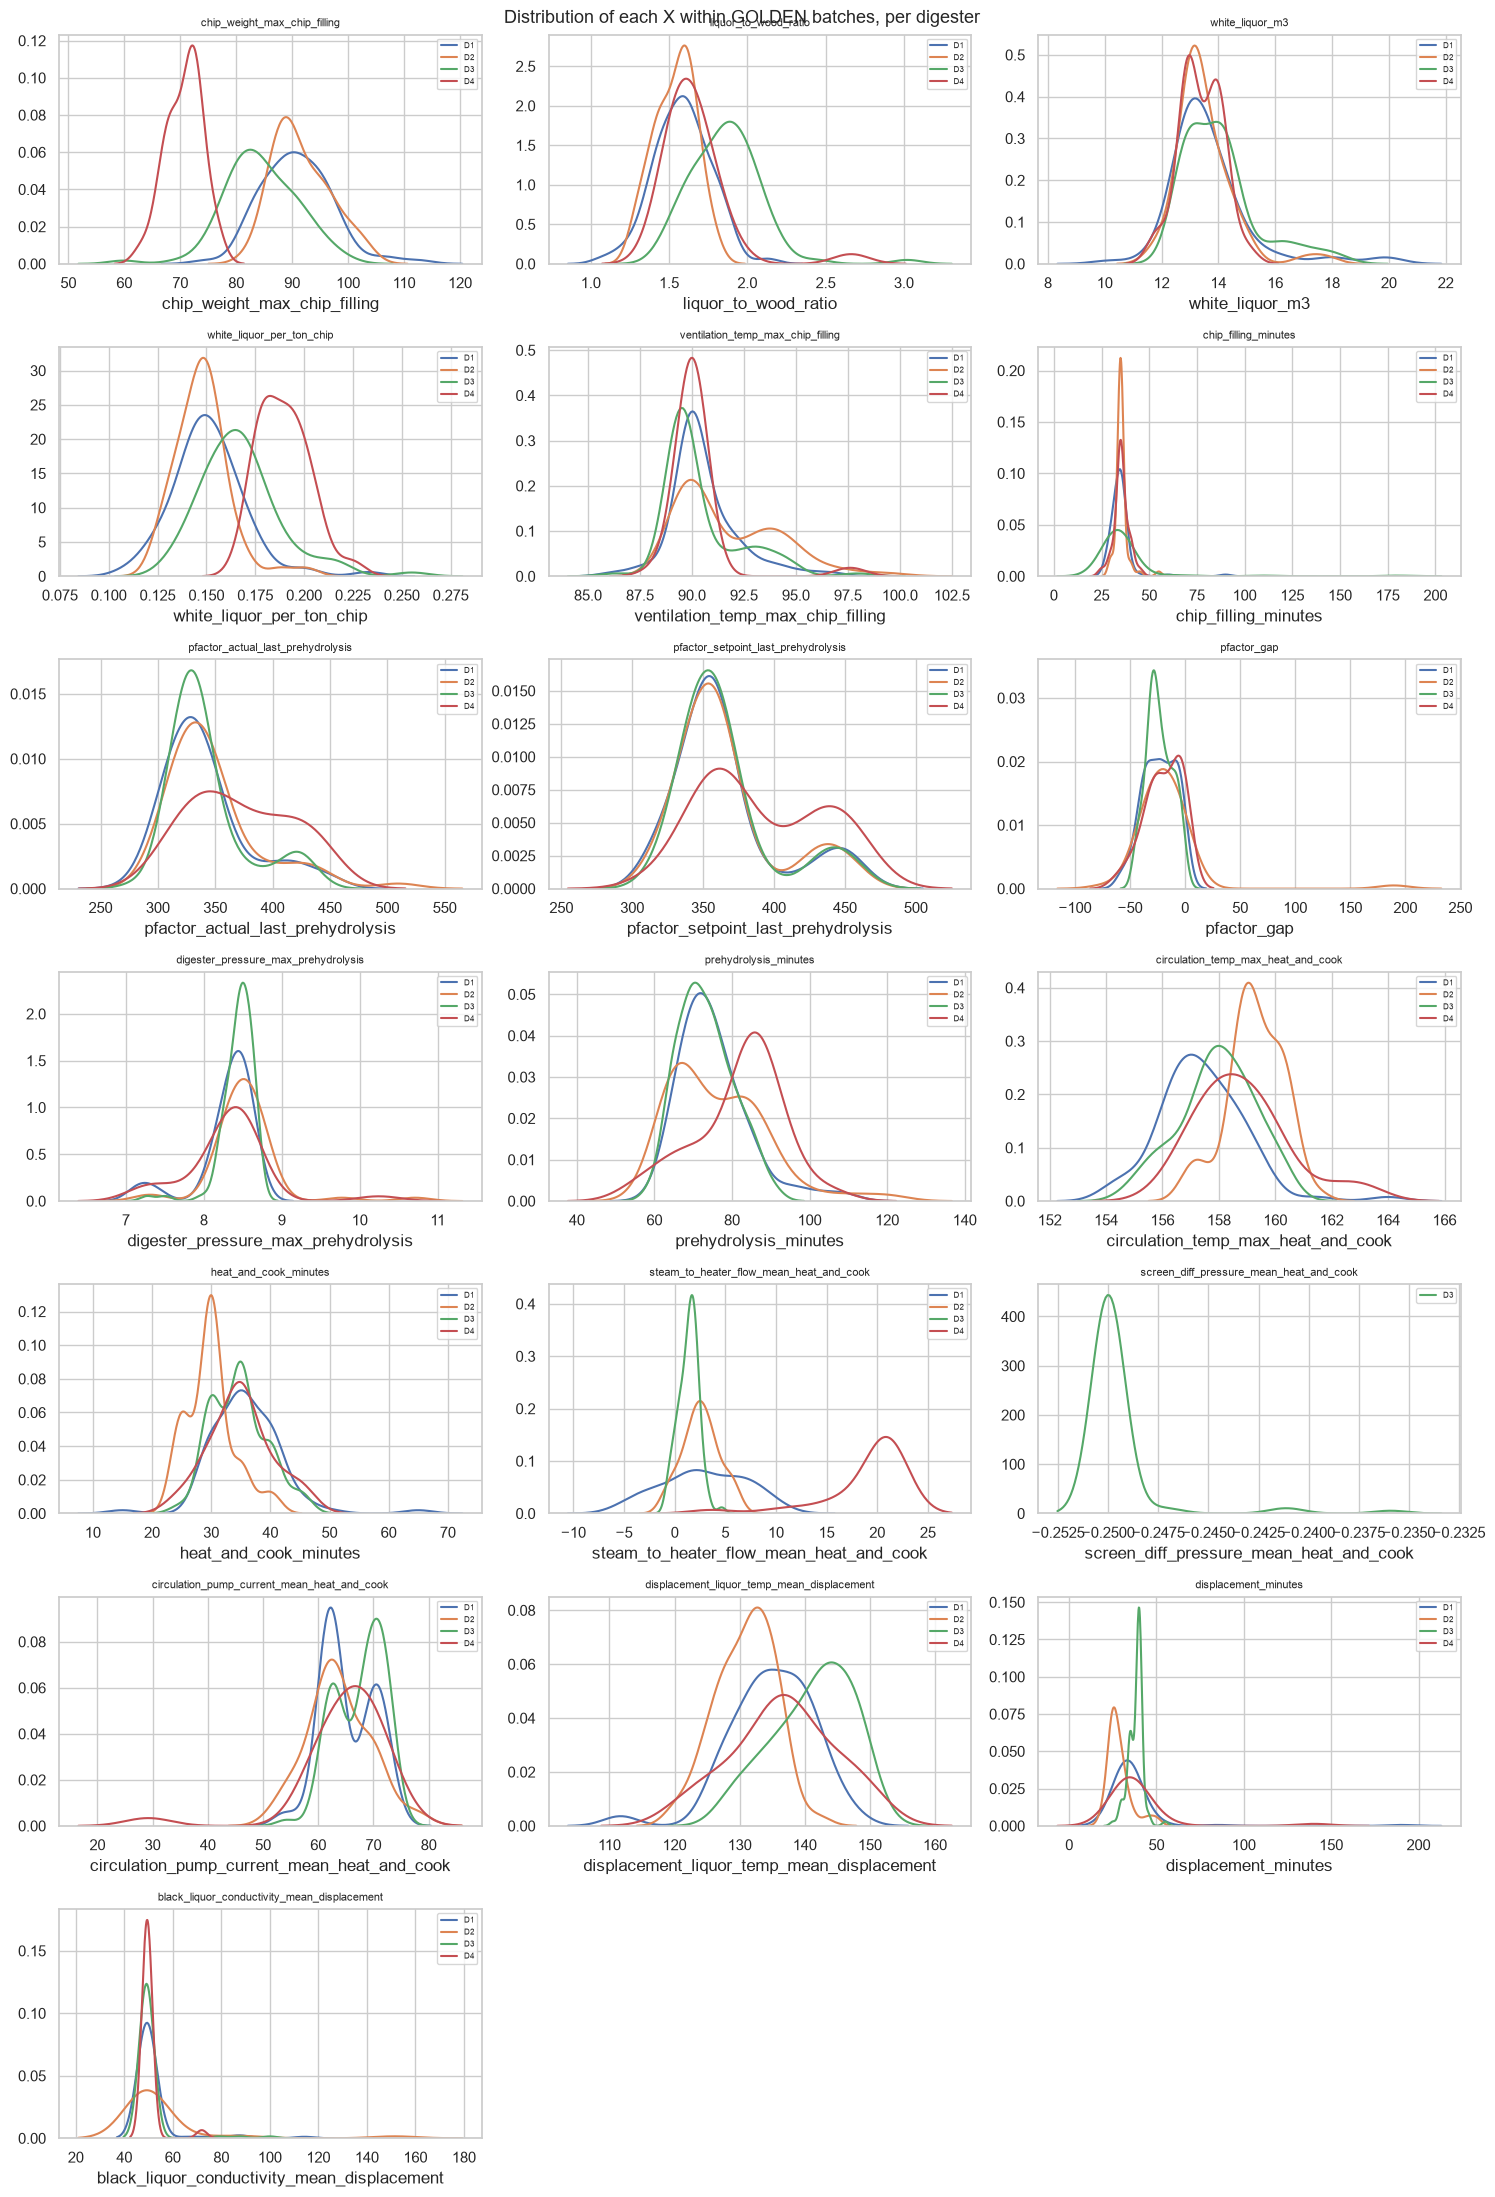

Golden window per digester - example: white_liquor_per_ton_chip


,N,p10,median,p90
Digester,,,,
D1,83,0.13,0.15,0.17
D2,55,0.13,0.15,0.16
D3,85,0.14,0.17,0.19
D4,28,0.18,0.19,0.20


In [60]:
def golden_window_by_digester(p):
    """Golden p10 / median / p90 of one X, per digester."""
    rows = []
    for d in sorted(golden["digester"].dropna().unique()):
        g = golden[golden["digester"] == d][p].dropna()
        if len(g) >= MIN_N:
            rows.append({"Digester": f"D{int(d)}", "N": len(g),
                         "p10": g.quantile(.10), "median": g.median(), "p90": g.quantile(.90)})
    return pd.DataFrame(rows).set_index("Digester").round(2)


# distribution of each X within GOLDEN only, one KDE line per digester
cols = [p for p in GOLDEN_X if golden[p].dropna().shape[0] >= MIN_N]
ncol = 3
nrow = int(np.ceil(len(cols) / ncol))
digs = sorted(golden["digester"].dropna().unique())
fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 3.2 * nrow))
for ax, p in zip(axes.ravel(), cols):
    for d in digs:
        g = golden[golden["digester"] == d][p].dropna()
        if len(g) >= MIN_N:
            sns.kdeplot(g, ax=ax, label=f"D{int(d)}", color=f"C{int(d) - 1}", warn_singular=False)
    ax.set_title(p, fontsize=8)
    ax.set_ylabel("")
    ax.legend(fontsize=6)
for ax in axes.ravel()[len(cols):]:
    ax.set_visible(False)
fig.suptitle("Distribution of each X within GOLDEN batches, per digester", fontsize=13)
plt.tight_layout()
plt.show()

# example window table for white liquor per ton of chip (edit the column to inspect any X)
print("Golden window per digester - example: white_liquor_per_ton_chip")
display(golden_window_by_digester("white_liquor_per_ton_chip"))
